# Product Sales Forecasting
### Forecasting daily sales for 365 retail stores, 61 days ahead

**Author:** Guntuku Hariprasad · **Repository:** [github.com/dot-hpg/sales-forecasting](https://github.com/dot-hpg/sales-forecasting)

---

## 1. Problem statement

A retail chain runs **365 stores** across 4 store formats, 5 location types and 4 regions. Management needs a reliable forecast of **daily sales per store** for the next two months (1 June to 31 July 2019) so that it can:

* **Plan inventory**: stock the right quantity per store and avoid stock-outs and over-stock,
* **Plan finances**: set realistic revenue targets and budgets,
* **Plan marketing**: decide when and where discount campaigns pay off,
* **Plan operations**: staff stores and schedule the supply chain around demand peaks.

**Forecasting target:** `Sales` per store per day, for the 61 days after the last observed date.

**Target metrics.**
* **WAPE** (weighted absolute percentage error = total absolute error / total sales) is the **primary business metric**: it reads as "how wrong are we, as a percentage of sales" and is not distorted by small days.
* **MAPE**, **MAE**, **RMSE** and **R²** are reported alongside, as the brief asks.

**Approach in one line:** understand the drivers with EDA and statistical tests, then build a single *global* gradient-boosted model over all stores using only information that is known when the forecast is made, validate it with rolling-origin cross-validation that mimics the real 61-day horizon, and deploy it as a mobile-friendly web app and a REST API.

### Dataset

| Column | Meaning |
|---|---|
| `ID` | Unique record id |
| `Store_id` | Store identifier (1 to 365) |
| `Store_Type` | Store format (S1 to S4) |
| `Location_Type` | Location category (L1 to L5) |
| `Region_Code` | Region (R1 to R4) |
| `Date` | Day of the record |
| `Holiday` | 1 if the day is a public holiday |
| `Discount` | Yes if the store ran a discount that day |
| `#Order` | Number of orders that day (**train only**) |
| `Sales` | Sales value that day (**target, train only**) |

`TRAIN.csv` covers 1 Jan 2018 to 31 May 2019 (188,340 rows). `TEST_FINAL.csv` covers 1 Jun 2019 to 31 Jul 2019 (22,265 rows) and has no `#Order` or `Sales`, which is exactly the situation of a real forecast: holidays and the discount plan are known in advance, orders and sales are not.

### Contents
1. Problem statement · 2. Setup · 3. Data quality · 4. Univariate analysis · 5. Bivariate analysis · 6. Time-series analysis · 7. Hypothesis testing · 8. Feature engineering · 9. Validation design · 10. Modelling (baselines, ML, statistical models) · 11. Tuning · 12. Final evaluation and error analysis · 13. Explainability · 14. Final forecast · 15. Insights and recommendations · 16. Deployment

## 2. Setup

In [1]:
import sys, warnings, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # make the `forecasting` package importable
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from forecasting import build_features, evaluate, metrics_table, load_train_test, SalesForecaster
from forecasting.features import FEATURES, ABLATION_FEATURES
from forecasting.model import LGBM_PARAMS, training_rows
from forecasting.config import HORIZON, PROCESSED_DIR, FIGURE_DIR
from forecasting.style import use_notebook_style, SERIES, BLUE, ORANGE, AQUA, YELLOW, INK_2, MUTED, SEQUENTIAL

use_notebook_style()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)
money = mtick.FuncFormatter(lambda v, _: f"{v/1e6:,.1f}M" if abs(v) >= 1e6 else f"{v/1e3:,.0f}K")

def save(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png", bbox_inches="tight")

train, test = load_train_test()
print(f"train: {train.shape}, test: {test.shape}")
train.head()

train: (188340, 10), test: (22265, 8)


,ID,Store_id,Store_Type,Location_Type,Region_Code,Date,Holiday,Discount,Orders,Sales
0,T1000001,1,S1,L3,R1,2018-01-01,1,1,9,"7,011.840"
1,T1000608,1,S1,L3,R1,2018-01-02,0,1,60,"42,369.000"
2,T1001047,1,S1,L3,R1,2018-01-03,0,1,72,"50,037.000"
3,T1001208,1,S1,L3,R1,2018-01-04,0,1,64,"44,397.000"
4,T1001753,1,S1,L3,R1,2018-01-05,0,1,63,"47,604.000"


## 3. Data quality checks

In [2]:
quality = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "missing": train.isna().sum(),
    "unique": train.nunique(),
})
display(quality)
print("Duplicate rows:", train.duplicated().sum(), "| duplicate (store, date) pairs:", train.duplicated(["Store_id", "Date"]).sum())
print("Date range:", train.Date.min().date(), "to", train.Date.max().date(), f"({train.Date.nunique()} days)")
print("Complete store x date grid:", len(train) == train.Store_id.nunique() * train.Date.nunique())
print("Stores with changing attributes:", (train.groupby("Store_id")[["Store_Type", "Location_Type", "Region_Code"]].nunique() > 1).sum().sum())
print("Holiday flag is the same for every store on a date:", train.groupby("Date").Holiday.nunique().max() == 1)
print("Test stores all seen in train:", set(test.Store_id) <= set(train.Store_id))

,dtype,missing,unique
ID,str,0,188340
Store_id,int64,0,365
Store_Type,str,0,4
Location_Type,str,0,5
Region_Code,str,0,4
Date,datetime64[us],0,516
Holiday,int64,0,2
Discount,int64,0,2
Orders,int64,0,299
Sales,float64,0,47422


Duplicate rows: 0 | duplicate (store, date) pairs: 0
Date range: 2018-01-01 to 2019-05-31 (516 days)
Complete store x date grid: True
Stores with changing attributes: 0
Holiday flag is the same for every store on a date: True
Test stores all seen in train: True


In [3]:
zero = train[train.Sales == 0]
print(f"Zero-sales rows: {len(zero)} ({len(zero)/len(train):.3%}), orders on those days: {zero.Orders.sum()}")
display(zero[["Store_id", "Date", "Holiday", "Discount", "Orders", "Sales"]].head(8))

q1, q3 = train.Sales.quantile([.25, .75]); iqr = q3 - q1
hi = train.Sales > q3 + 1.5 * iqr
print(f"IQR outliers (high): {hi.sum():,} rows ({hi.mean():.2%}); share of them on discount days: {train.loc[hi, 'Discount'].mean():.0%}")
display(train.Sales.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame().T)

Zero-sales rows: 19 (0.010%), orders on those days: 0


,Store_id,Date,Holiday,Discount,Orders,Sales
5948,12,2018-09-30,0,0,0,0.000
5949,12,2018-10-01,0,0,0,0.000
5950,12,2018-10-02,1,0,0,0.000
19916,39,2018-11-05,0,0,0,0.000
19917,39,2018-11-06,1,0,0,0.000
19918,39,2018-11-07,1,0,0,0.000
105204,204,2019-04-02,0,0,0,0.000
105205,204,2019-04-03,0,0,0,0.000


IQR outliers (high): 5,843 rows (3.10%); share of them on discount days: 73%


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Sales,"188,340.000","42,784.328","18,456.708",0.000,"7,081.680","19,191.000","30,426.000","39,678.000","51,909.000","76,809.300","102,159.000","247,215.000"


> **Insights: data quality**
> * The data is clean: **no missing values, no duplicates**, and a **complete grid** of 365 stores × 516 days. Store attributes never change, and the holiday flag is a single chain-wide calendar.
> * **19 zero-sales rows (0.01%)** all have zero orders and come in runs of 2 to 3 days at the same store: these are **store closures**, not demand. They are excluded from training and from MAPE, so the model doesn't learn to predict closures it can't foresee.
> * **3.1% of rows are high outliers** by the IQR rule, and **73% of them fall on discount days**. They are genuine promotion peaks, not errors, so they are **kept**. The log transform used for modelling reduces their leverage.

## 4. Univariate analysis

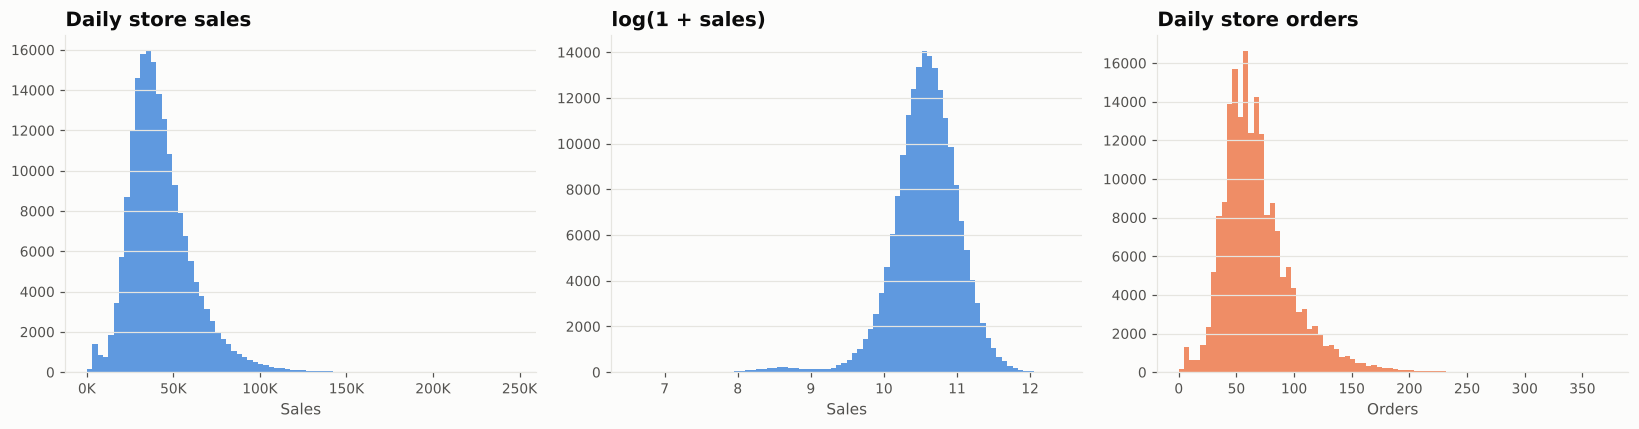

Skewness: sales 1.25, log sales -1.02, orders 1.37


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(train.Sales, bins=80, ax=axes[0], color=BLUE, edgecolor="none")
axes[0].set_title("Daily store sales"); axes[0].xaxis.set_major_formatter(money)
sns.histplot(np.log1p(train.Sales[train.Sales > 0]), bins=80, ax=axes[1], color=BLUE, edgecolor="none")
axes[1].set_title("log(1 + sales)")
sns.histplot(train.Orders, bins=80, ax=axes[2], color=ORANGE, edgecolor="none")
axes[2].set_title("Daily store orders")
for a in axes: a.set_ylabel("")
plt.tight_layout(); save(fig, "01_distributions"); plt.show()
print(f"Skewness: sales {train.Sales.skew():.2f}, log sales {np.log1p(train.Sales[train.Sales>0]).skew():.2f}, orders {train.Orders.skew():.2f}")

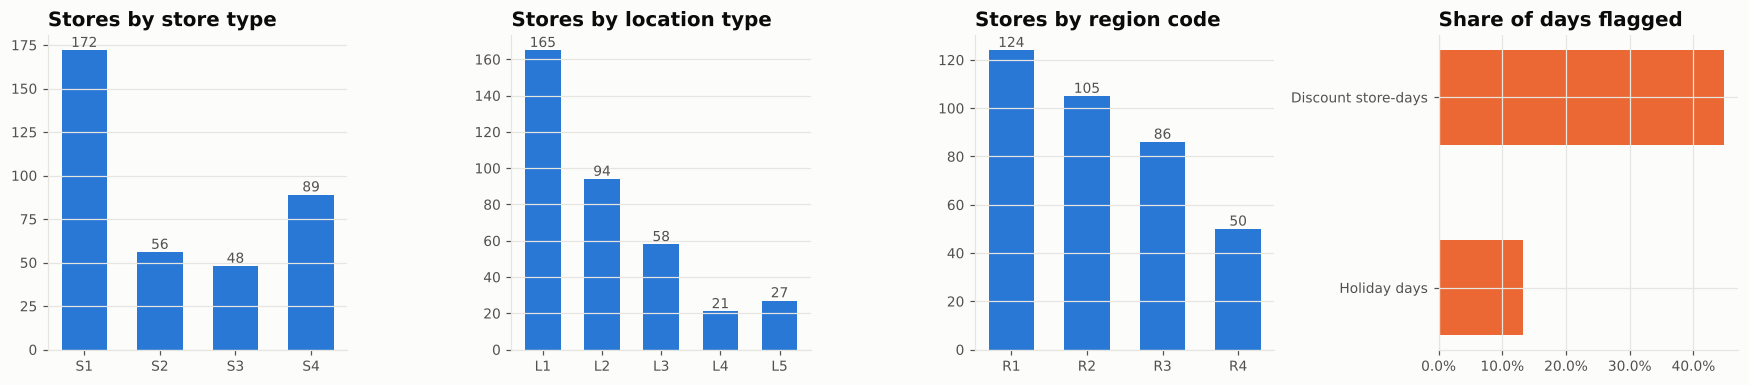

In [5]:
stores = train.drop_duplicates("Store_id")
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col in zip(axes[:3], ["Store_Type", "Location_Type", "Region_Code"]):
    vc = stores[col].value_counts().sort_index()
    ax.bar(vc.index, vc.values, color=BLUE, width=0.6)
    for x, v in zip(vc.index, vc.values): ax.text(x, v, str(v), ha="center", va="bottom", fontsize=9, color=INK_2)
    ax.set_title(f"Stores by {col.replace('_', ' ').lower()}")
flags = pd.Series({"Holiday days": train.drop_duplicates("Date").Holiday.mean(), "Discount store-days": train.Discount.mean()})
axes[3].barh(flags.index, flags.values, color=ORANGE, height=0.5); axes[3].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[3].set_title("Share of days flagged"); axes[3].grid(axis="x")
plt.tight_layout(); save(fig, "02_categoricals"); plt.show()

> **Insights: univariate**
> * Daily store sales are **right-skewed** (skew 1.25; median 39.7K, mean 42.8K, max 247K). The log transform overcorrects slightly (skew −1.0, driven by a few very small days) but makes the distribution far more symmetric, and it turns multiplicative effects into additive ones. That is why the models learn log-sales.
> * The chain is dominated by **S1 stores (172 of 365)** and **L1 locations (165)**, while L4 and L5 have only 21 and 27 stores. Segment averages for the small groups are therefore less certain.
> * **13% of days are public holidays** (68 of 516), and **45% of store-days are discount days**, so promotions are a normal part of the business, not a rare event.

## 5. Bivariate analysis

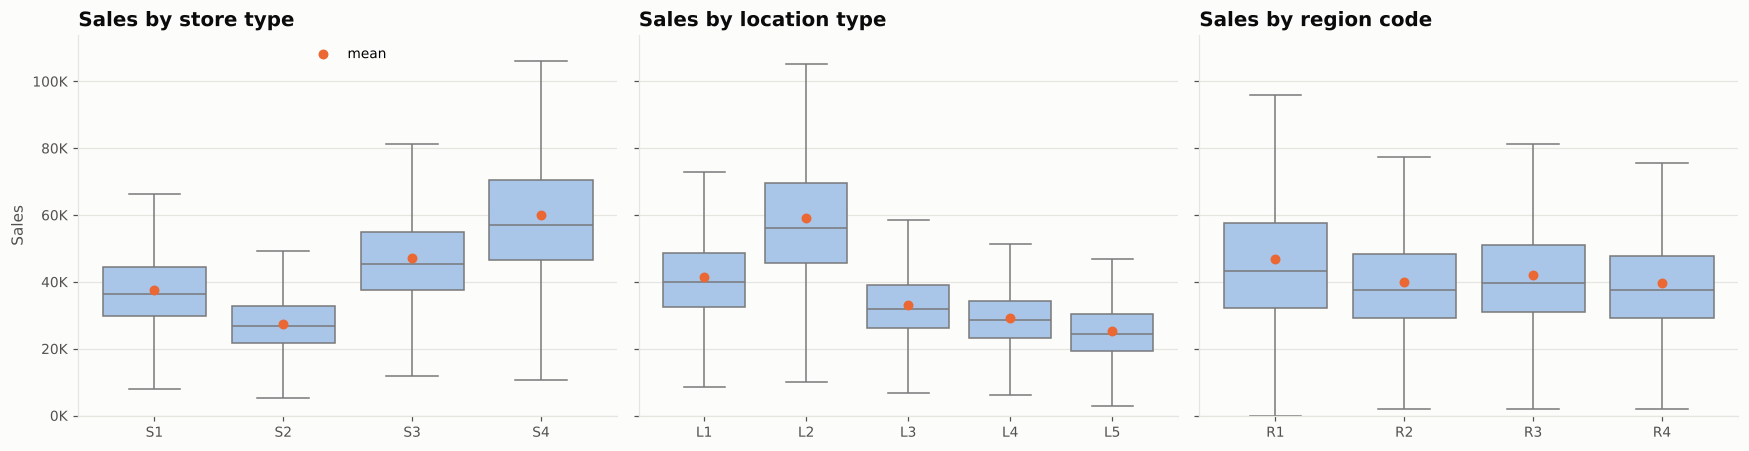

stores  avg_daily_sales  total_sales_share
Store_Type    S1     172       37,676.512             41.497
              S2      56       27,530.828              9.873
              S3      48       47,063.068             14.466
              S4      89       59,945.686             34.164
Location_Type L1     165       41,453.598             43.799
              L2      94       59,231.480             35.654
              L3      58       33,072.258             12.283
              L4      21       29,067.414              3.909
              L5      27       25,187.787              4.355
Region_Code   R1     124       46,765.488             37.134
              R2     105       40,054.847             26.932
              R3      86       42,144.517             23.209
              R4      50       39,743.434             12.725

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, col in zip(axes, ["Store_Type", "Location_Type", "Region_Code"]):
    order = sorted(train[col].unique())
    sns.boxplot(data=train, x=col, y="Sales", order=order, ax=ax, color=SEQUENTIAL[1], fliersize=0, linewidth=1)
    means = train.groupby(col).Sales.mean().reindex(order)
    ax.scatter(range(len(order)), means, color=ORANGE, zorder=5, s=30, label="mean")
    ax.set_ylim(0, train.Sales.quantile(.995)); ax.yaxis.set_major_formatter(money)
    ax.set_title(f"Sales by {col.replace('_', ' ').lower()}"); ax.set_xlabel("")
axes[0].legend()
plt.tight_layout(); save(fig, "03_sales_by_segment"); plt.show()
seg = pd.concat({c: train.groupby(c).agg(stores=("Store_id", "nunique"), avg_daily_sales=("Sales", "mean"),
                 total_sales_share=("Sales", "sum")) for c in ["Store_Type", "Location_Type", "Region_Code"]})
seg["total_sales_share"] = seg.total_sales_share / train.Sales.sum() * 100
seg

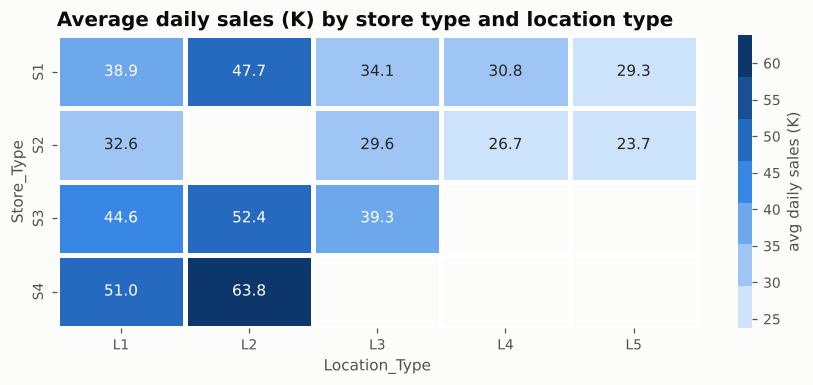

Number of stores in each cell:


Location_Type,L1,L2,L3,L4,L5
Store_Type,,,,,
S1,103,14,36,12,7
S2,9,0,18,9,20
S3,26,18,4,0,0
S4,27,62,0,0,0


In [7]:
pivot = train.pivot_table(index="Store_Type", columns="Location_Type", values="Sales", aggfunc="mean")
counts = train.drop_duplicates("Store_id").pivot_table(index="Store_Type", columns="Location_Type", values="Store_id", aggfunc="count")
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(pivot / 1e3, annot=True, fmt=".1f", cmap=sns.color_palette(SEQUENTIAL, as_cmap=True), ax=ax,
            cbar_kws={"label": "avg daily sales (K)"}, linewidths=2, linecolor="white")
ax.set_title("Average daily sales (K) by store type and location type"); ax.grid(False)
plt.tight_layout(); save(fig, "04_type_location_heatmap"); plt.show()
print("Number of stores in each cell:"); display(counts.fillna(0).astype(int))

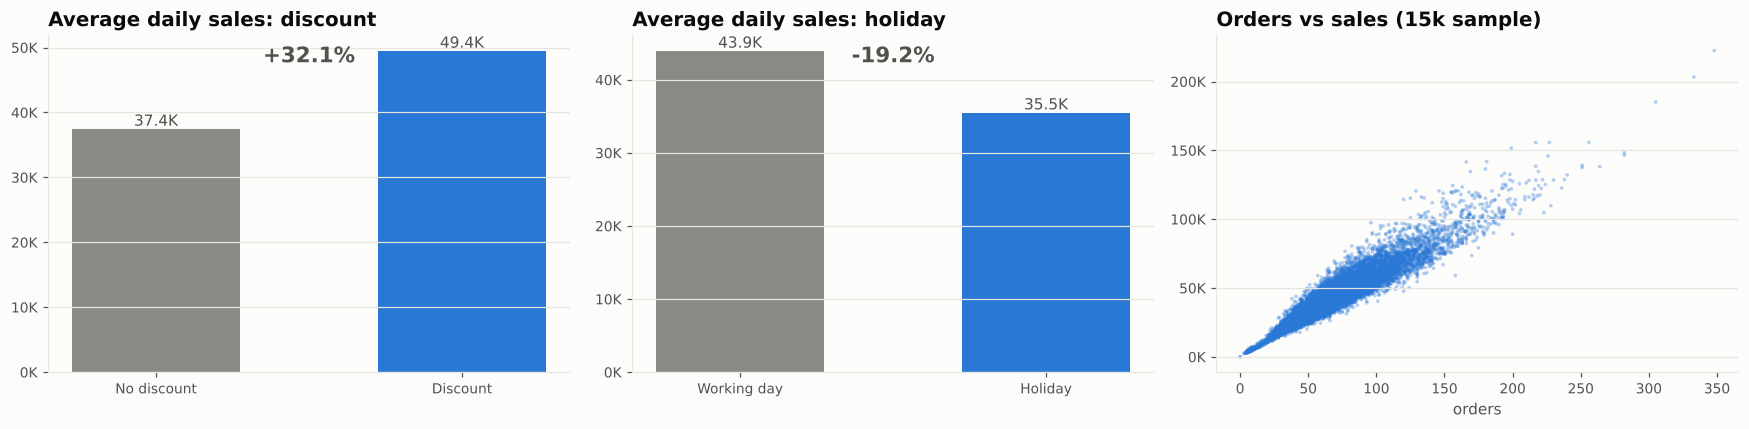

Average order value by store type:


Store_Type,S1,S2,S3,S4
avg_order_value,647.034,677.112,634.889,586.753


Discount uplift by store type:


Store_Type,S1,S2,S3,S4
uplift_%,33.007,32.800,34.229,29.555


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, labels in [(axes[0], "Discount", ["No discount", "Discount"]), (axes[1], "Holiday", ["Working day", "Holiday"])]:
    m = train.groupby(col).Sales.mean()
    ax.bar(labels, m.values, color=[MUTED, BLUE], width=0.55)
    for i, v in enumerate(m.values): ax.text(i, v, f"{v/1e3:,.1f}K", ha="center", va="bottom", color=INK_2)
    ax.set_title(f"Average daily sales: {col.lower()}"); ax.yaxis.set_major_formatter(money)
    ax.text(0.5, 0.92, f"{m.iloc[1]/m.iloc[0]-1:+.1%}", transform=ax.transAxes, ha="center", fontsize=14, color=INK_2, weight="bold")
s = train.sample(15000, random_state=1)
axes[2].scatter(s.Orders, s.Sales, s=6, alpha=.35, color=BLUE, edgecolors="none")
axes[2].set_title("Orders vs sales (15k sample)"); axes[2].set_xlabel("orders"); axes[2].yaxis.set_major_formatter(money)
plt.tight_layout(); save(fig, "05_discount_holiday_orders"); plt.show()

train["AOV"] = train.Sales / train.Orders.replace(0, np.nan)
print("Average order value by store type:"); display(train.groupby("Store_Type").AOV.mean().to_frame("avg_order_value").T)
print("Discount uplift by store type:")
display((train.groupby(["Store_Type", "Discount"]).Sales.mean().unstack().pipe(lambda t: t[1] / t[0] - 1) * 100).to_frame("uplift_%").T)

> **Insights: bivariate**
> * **Store format and location drive the level of sales.** S4 stores average **59.9K/day** against 27.5K for S2. L2 locations average **59.2K** against 25.2K for L5. S4 and L2 overlap heavily (62 of 89 S4 stores sit in L2 locations), which makes S4-in-L2 the most valuable combination.
> * **S1 earns the largest share of revenue (41%)** because it has the most stores, not because its stores are strong. S4 earns 34% from only 89 stores.
> * **Region matters much less**: averages range only from 39.7K (R4) to 46.8K (R1).
> * **Discount days sell 32% more** on average and **holidays sell 19% less**. The discount uplift is similar in every store format (30 to 34%).
> * **Orders and sales move together almost perfectly** (scatter plot). S4 stores have the lowest average order value (587 vs 677 for S2), so their higher sales come from **more orders, not bigger baskets**.

## 6. Time-series analysis

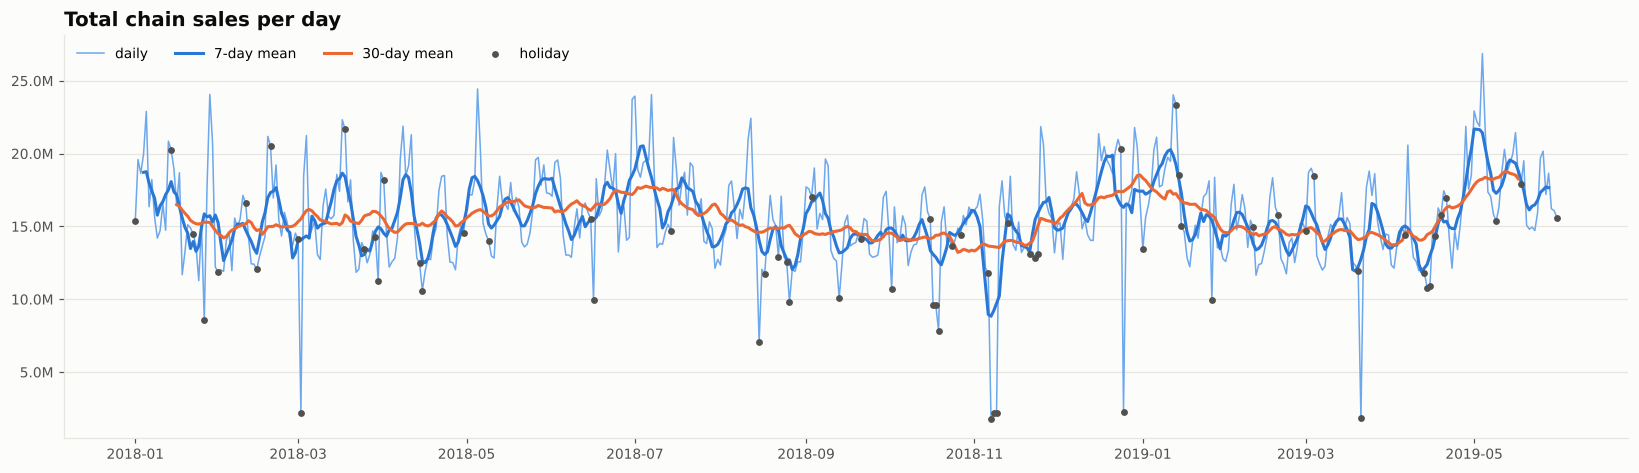

In [9]:
daily = train.groupby("Date").agg(Sales=("Sales", "sum"), Orders=("Orders", "sum"),
                                  Discount_share=("Discount", "mean"), Holiday=("Holiday", "max"))
fig, ax = plt.subplots(figsize=(15, 4.4))
ax.plot(daily.index, daily.Sales, color=SEQUENTIAL[2], lw=1, label="daily")
ax.plot(daily.index, daily.Sales.rolling(7, center=True).mean(), color=BLUE, lw=2, label="7-day mean")
ax.plot(daily.index, daily.Sales.rolling(30, center=True).mean(), color=ORANGE, lw=2, label="30-day mean")
hol = daily[daily.Holiday == 1]
ax.scatter(hol.index, hol.Sales, color=INK_2, s=12, zorder=5, label="holiday")
ax.yaxis.set_major_formatter(money); ax.set_title("Total chain sales per day"); ax.legend(ncol=4, loc="upper left")
plt.tight_layout(); save(fig, "06_daily_sales_trend"); plt.show()

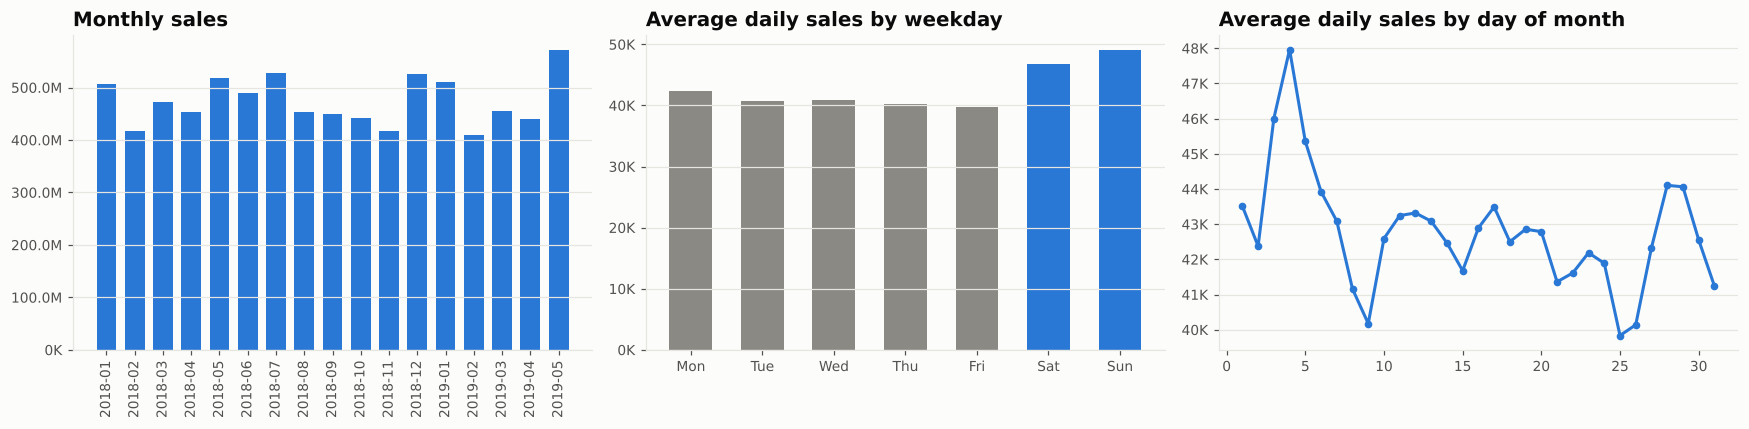

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
monthly = train.groupby(train.Date.dt.to_period("M")).Sales.sum()
axes[0].bar(monthly.index.astype(str), monthly.values, color=BLUE, width=0.7)
axes[0].tick_params(axis="x", rotation=90); axes[0].yaxis.set_major_formatter(money); axes[0].set_title("Monthly sales")
dow = train.groupby(train.Date.dt.dayofweek).Sales.mean()
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values, color=[MUTED]*5 + [BLUE]*2, width=0.6)
axes[1].yaxis.set_major_formatter(money); axes[1].set_title("Average daily sales by weekday")
dom = train.groupby(train.Date.dt.day).Sales.mean()
axes[2].plot(dom.index, dom.values, marker="o", ms=4, color=BLUE); axes[2].yaxis.set_major_formatter(money)
axes[2].set_title("Average daily sales by day of month")
plt.tight_layout(); save(fig, "07_seasonality"); plt.show()

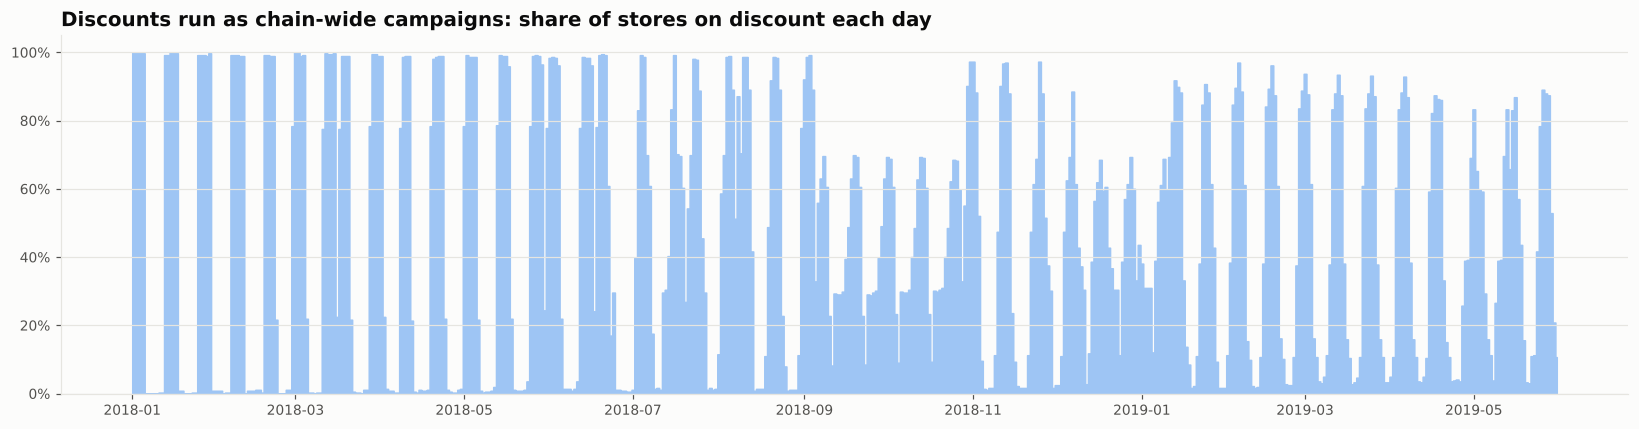

Correlation between daily discount share and daily chain sales: 0.50
Days where >90% or <10% of stores are on discount: 49%


In [11]:
fig, ax = plt.subplots(figsize=(15, 4))
ax.fill_between(daily.index, daily.Discount_share, color=SEQUENTIAL[1], step="mid", label="share of stores on discount")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylim(0, 1.05)
ax.set_title("Discounts run as chain-wide campaigns: share of stores on discount each day")
plt.tight_layout(); save(fig, "08_discount_campaigns"); plt.show()
print(f"Correlation between daily discount share and daily chain sales: {daily[['Discount_share','Sales']].corr().iloc[0,1]:.2f}")
print(f"Days where >90% or <10% of stores are on discount: {((daily.Discount_share>.9)|(daily.Discount_share<.1)).mean():.0%}")

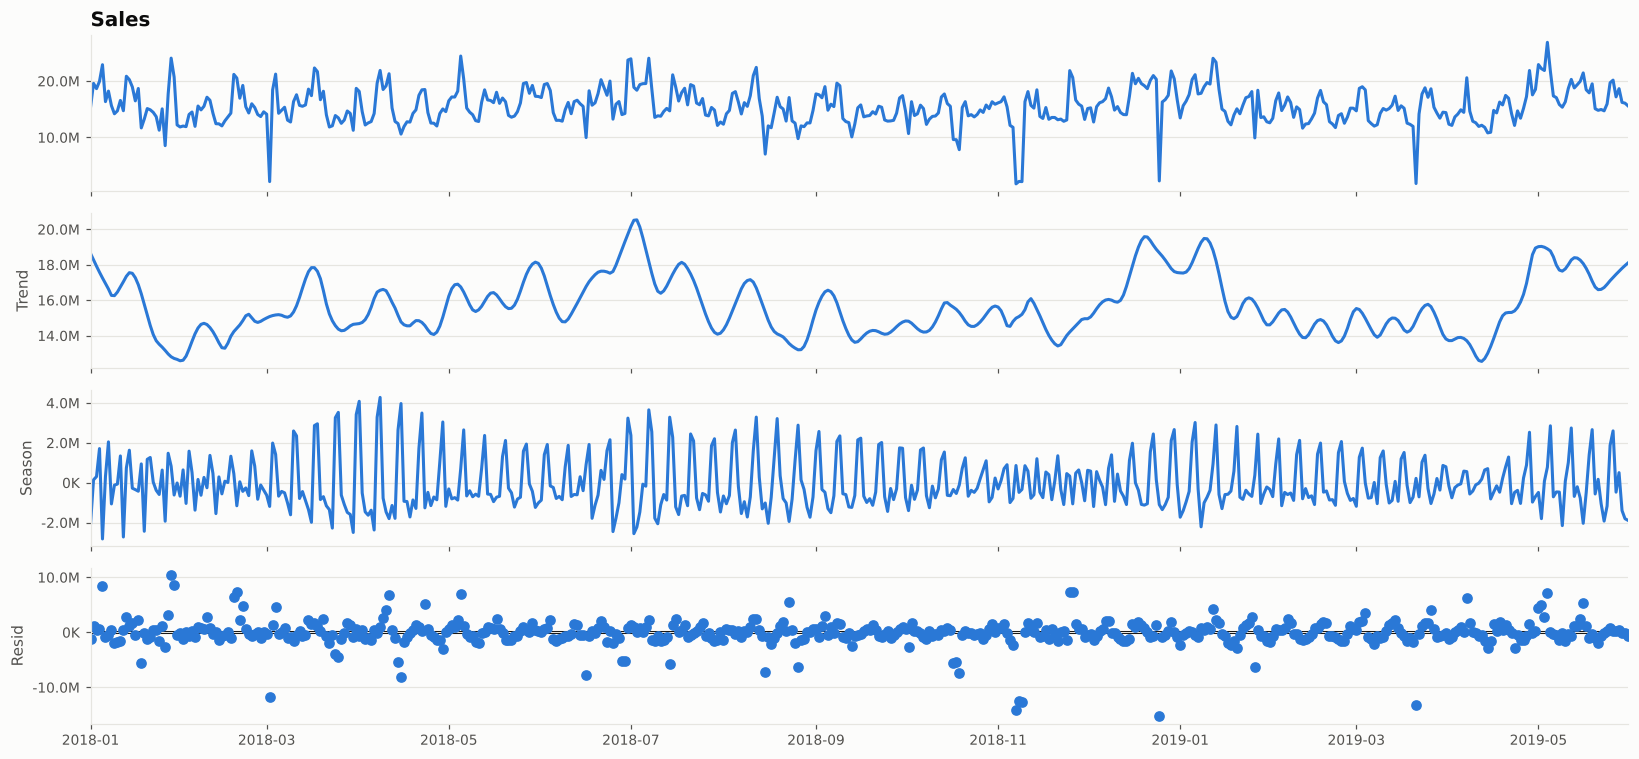

Strength of weekly seasonality: 0.18 | strength of trend: 0.36  (0 = none, 1 = strong)


In [12]:
stl = STL(daily.Sales, period=7, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(15, 7)
for a in fig.axes: a.yaxis.set_major_formatter(money)
plt.tight_layout(); save(fig, "09_stl_decomposition"); plt.show()
strength_seasonal = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())
strength_trend = max(0, 1 - stl.resid.var() / (stl.resid + stl.trend).var())
print(f"Strength of weekly seasonality: {strength_seasonal:.2f} | strength of trend: {strength_trend:.2f}  (0 = none, 1 = strong)")

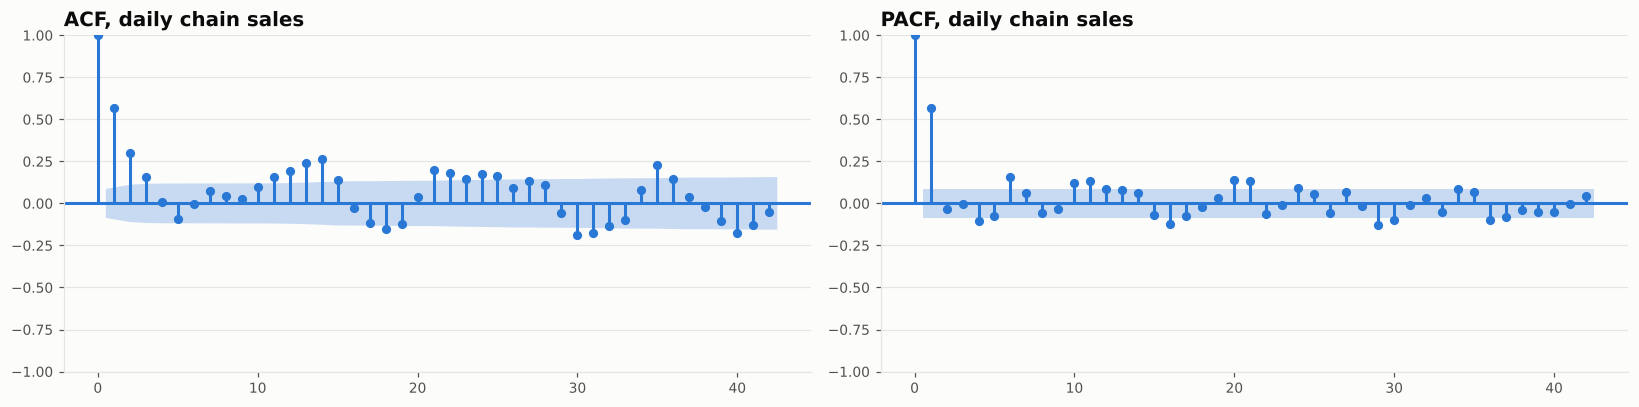

ADF statistic -3.52, p-value 0.0074  -> H0 (unit root) rejected: stationary
KPSS statistic 0.12, p-value 0.1000 -> H0 (stationary) not rejected: stationary


/tmp/ipykernel_3308/884411345.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  adf = adfuller(daily.Sales, autolag="AIC"); kp = kpss(daily.Sales, nlags="auto")


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
plot_acf(daily.Sales, lags=42, ax=axes[0], color=BLUE, vlines_kwargs={"colors": BLUE}); axes[0].set_title("ACF, daily chain sales")
plot_pacf(daily.Sales, lags=42, ax=axes[1], color=BLUE, vlines_kwargs={"colors": BLUE}, method="ywm"); axes[1].set_title("PACF, daily chain sales")
plt.tight_layout(); save(fig, "10_acf_pacf"); plt.show()
adf = adfuller(daily.Sales, autolag="AIC"); kp = kpss(daily.Sales, nlags="auto")
print(f"ADF statistic {adf[0]:.2f}, p-value {adf[1]:.4f}  -> H0 (unit root) {'rejected: stationary' if adf[1] < .05 else 'not rejected'}")
print(f"KPSS statistic {kp[0]:.2f}, p-value {kp[1]:.4f} -> H0 (stationary) {'rejected' if kp[1] < .05 else 'not rejected: stationary'}")

> **Insights: time series**
> * **There is no long-term growth trend.** Monthly sales move between 408M and 571M with no upward drift (Jan to Apr 2019 were within ±3.5% of the same months in 2018). The series is **stationary** by both the ADF test (p = 0.007) and the KPSS test (p > 0.1).
> * There is clear **weekly seasonality**: **Sunday is +15% and Saturday +9%** above the weekly average, while **Friday is the weakest day (−7%)**.
> * There are **seasonal peaks in January, May, July and December**, and dips in February and November. **May 2019 was the strongest month in the data (571M, +10% on May 2018)**.
> * **Discounts are chain-wide campaigns**: on half of all days either more than 90% or fewer than 10% of stores are on discount, and the daily discount share correlates **0.50** with chain sales. Days when more than 90% of stores run a discount average **17.4M** in chain sales, against **13.6M** when fewer than 10% do.
> * **Holiday spikes downward** are the sharpest movements in the series. The STL decomposition shows that weekly seasonality explains only part of the variation. Most of the rest comes from planned events (campaigns and holidays), which is why the model needs event features rather than a pure time-series approach.

## 7. Hypothesis testing

With 188k rows almost any difference is "statistically significant", so every test below reports an **effect size** next to the p-value, and the main tests are repeated at the **store level** (one value per store), which removes the pseudo-replication of many days from the same store. Significance level α = 0.05 throughout. Sales are right-skewed, so each parametric test is paired with a non-parametric one.

In [14]:
results = []
def record(h, test, stat, p, effect, effect_name, conclusion):
    results.append({"hypothesis": h, "test": test, "statistic": stat, "p_value": p,
                    "effect_size": effect, "effect_measure": effect_name, "conclusion": conclusion})

def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var() + (nb - 1) * b.var()) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp

def two_group(h, df, col, hi=1, lo=0):
    a, b = df.loc[df[col] == hi, "Sales"], df.loc[df[col] == lo, "Sales"]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    record(h, "Welch t-test (store-days)", t, p, cohens_d(a, b), "Cohen's d", "Reject H0" if p < .05 else "Fail to reject H0")
    u, pu = stats.mannwhitneyu(a, b)
    record(h, "Mann-Whitney U (store-days)", u, pu, 2 * u / (len(a) * len(b)) - 1, "rank-biserial r", "Reject H0" if pu < .05 else "Fail to reject H0")
    per_store = df.groupby(["Store_id", col]).Sales.mean().unstack().dropna()
    t2, p2 = stats.ttest_rel(per_store[hi], per_store[lo])
    uplift = (per_store[hi] / per_store[lo] - 1)
    record(h, "Paired t-test (store means)", t2, p2, uplift.mean() * 100, "mean uplift %", "Reject H0" if p2 < .05 else "Fail to reject H0")
    w, pw = stats.wilcoxon(per_store[hi], per_store[lo])
    record(h, "Wilcoxon signed-rank (store means)", w, pw, (uplift > 0).mean() * 100, "% stores higher", "Reject H0" if pw < .05 else "Fail to reject H0")
    return per_store, uplift

### H1. Discounts increase sales
* H0: mean sales on discount days = mean sales on non-discount days
* H1: they differ

,statistic,p_value,effect_size,effect_measure,conclusion
test,,,,,
Welch t-test (store-days),145.929,0.000,0.689,Cohen's d,Reject H0
Mann-Whitney U (store-days),"6,190,447,035.500",0.000,0.412,rank-biserial r,Reject H0
Paired t-test (store means),40.828,0.000,33.517,mean uplift %,Reject H0
Wilcoxon signed-rank (store means),1.000,0.000,99.726,% stores higher,Reject H0


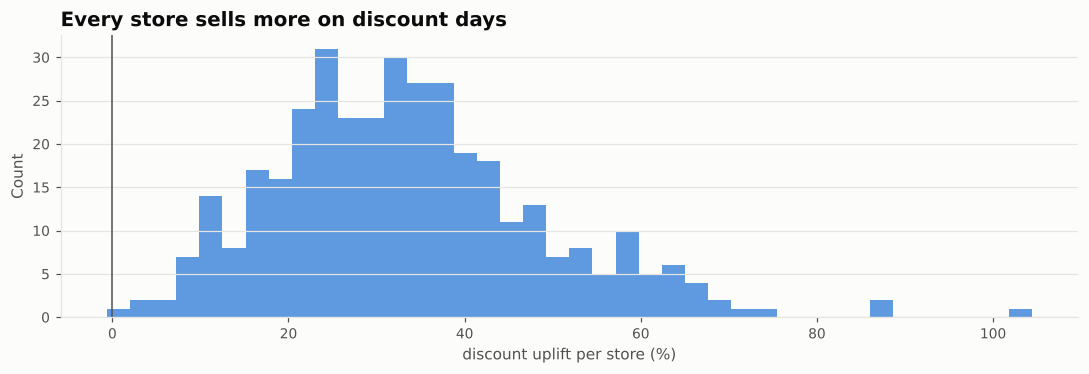

In [15]:
per_store_disc, disc_uplift = two_group("H1 Discount affects sales", train, "Discount")
display(pd.DataFrame(results[-4:]).set_index("test")[["statistic", "p_value", "effect_size", "effect_measure", "conclusion"]])
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.histplot(disc_uplift * 100, bins=40, color=BLUE, edgecolor="none", ax=ax)
ax.axvline(0, color=INK_2, lw=1); ax.set_xlabel("discount uplift per store (%)"); ax.set_title("Every store sells more on discount days")
plt.tight_layout(); save(fig, "11_discount_uplift_by_store"); plt.show()

### H2. Holidays change sales
* H0: mean sales on holidays = mean sales on working days
* H1: they differ

In [16]:
per_store_hol, hol_effect = two_group("H2 Holiday affects sales", train, "Holiday")
display(pd.DataFrame(results[-4:]).set_index("test")[["statistic", "p_value", "effect_size", "effect_measure", "conclusion"]])

,statistic,p_value,effect_size,effect_measure,conclusion
test,,,,,
Welch t-test (store-days),-66.176,0.000,-0.463,Cohen's d,Reject H0
Mann-Whitney U (store-days),"1,478,686,923.500",0.000,-0.271,rank-biserial r,Reject H0
Paired t-test (store means),-55.990,0.000,-19.097,mean uplift %,Reject H0
Wilcoxon signed-rank (store means),0.000,0.000,0.000,% stores higher,Reject H0


### H3 to H5. Sales differ across store types, location types and regions
* H0: mean sales are equal across all groups
* H1: at least one group differs

One-way ANOVA (with Levene's test for equal variances), Welch's ANOVA when variances differ, Kruskal-Wallis as the non-parametric check, then Tukey HSD on store-level means to see *which* groups differ. Effect size: η² (share of variance explained).

In [17]:
store_means = train.groupby(["Store_id", "Store_Type", "Location_Type", "Region_Code"]).Sales.mean().reset_index()
for h, col in [("H3 Store type affects sales", "Store_Type"), ("H4 Location type affects sales", "Location_Type"), ("H5 Region affects sales", "Region_Code")]:
    groups = [g.Sales.values for _, g in train.groupby(col)]
    lev = stats.levene(*[g[:20000] for g in groups])
    f, p = stats.f_oneway(*groups)
    model = smf.ols(f"Sales ~ C({col})", data=train).fit()
    eta2 = model.rsquared
    record(h, "One-way ANOVA (store-days)", f, p, eta2, "eta squared", "Reject H0" if p < .05 else "Fail to reject H0")
    welch = sm.stats.anova_oneway(train.Sales, train[col], use_var="unequal")
    record(h, "Welch ANOVA (store-days)", welch.statistic, welch.pvalue, eta2, "eta squared", "Reject H0" if welch.pvalue < .05 else "Fail to reject H0")
    k, pk = stats.kruskal(*groups)
    record(h, "Kruskal-Wallis (store-days)", k, pk, (k - len(groups) + 1) / (len(train) - len(groups)), "epsilon squared", "Reject H0" if pk < .05 else "Fail to reject H0")
    sg = [g.Sales.values for _, g in store_means.groupby(col)]
    f2, p2 = stats.f_oneway(*sg)
    eta2_s = smf.ols(f"Sales ~ C({col})", data=store_means).fit().rsquared
    record(h, "One-way ANOVA (store means)", f2, p2, eta2_s, "eta squared", "Reject H0" if p2 < .05 else "Fail to reject H0")
    print(f"{col}: Levene p = {lev.pvalue:.2e} (variances {'differ' if lev.pvalue < .05 else 'equal'})")
display(pd.DataFrame(results[-12:]).set_index(["hypothesis", "test"])[["statistic", "p_value", "effect_size", "effect_measure", "conclusion"]])

Store_Type: Levene p = 0.00e+00 (variances differ)


Location_Type: Levene p = 0.00e+00 (variances differ)


Region_Code: Levene p = 1.87e-259 (variances differ)


statistic  \
hypothesis                     test                                     
H3 Store type affects sales    One-way ANOVA (store-days)  35,123.644   
                               Welch ANOVA (store-days)    32,696.207   
                               Kruskal-Wallis (store-days) 73,677.057   
                               One-way ANOVA (store means)    308.508   
H4 Location type affects sales One-way ANOVA (store-days)  25,338.874   
                               Welch ANOVA (store-days)    25,353.669   
                               Kruskal-Wallis (store-days) 72,945.842   
                               One-way ANOVA (store means)    211.587   
H5 Region affects sales        One-way ANOVA (store-days)   1,682.426   
                               Welch ANOVA (store-days)     1,491.213   
                               Kruskal-Wallis (store-days)  3,968.064   
                               One-way ANOVA (store means)      6.646   

                                                            p_value  \
hypothesis                     test                                   
H3 Store type affects sales    One-way ANOVA (store-days)     0.000   
                               Welch ANOVA (store-days)       0.000   
                               Kruskal-Wallis (store-days)    0.000   
                               One-way ANOVA (store means)    0.000   
H4 Location type affects sales One-way ANOVA (store-days)     0.000   
                               Welch ANOVA (store-days)       0.000   
                               Kruskal-Wallis (store-days)    0.000   
                               One-way ANOVA (store means)    0.000   
H5 Region affects sales        One-way ANOVA (store-days)     0.000   
                               Welch ANOVA (store-days)       0.000   
                               Kruskal-Wallis (store-days)    0.000   
                               One-way ANOVA (store means)    0.000   

                                                            effect_size  \
hypothesis                     test                                       
H3 Store type affects sales    One-way ANOVA (store-days)         0.359   
                               Welch ANOVA (store-days)           0.359   
                               Kruskal-Wallis (store-days)        0.391   
                               One-way ANOVA (store means)        0.719   
H4 Location type affects sales One-way ANOVA (store-days)         0.350   
                               Welch ANOVA (store-days)           0.350   
                               Kruskal-Wallis (store-days)        0.387   
                               One-way ANOVA (store means)        0.702   
H5 Region affects sales        One-way ANOVA (store-days)         0.026   
                               Welch ANOVA (store-days)           0.026   
                               Kruskal-Wallis (store-days)        0.021   
                               One-way ANOVA (store means)        0.052   

                                                             effect_measure  \
hypothesis                     test                                           
H3 Store type affects sales    One-way ANOVA (store-days)       eta squared   
                               Welch ANOVA (store-days)         eta squared   
                               Kruskal-Wallis (store-days)  epsilon squared   
                               One-way ANOVA (store means)      eta squared   
H4 Location type affects sales One-way ANOVA (store-days)       eta squared   
                               Welch ANOVA (store-days)         eta squared   
                               Kruskal-Wallis (store-days)  epsilon squared   
                               One-way ANOVA (store means)      eta squared   
H5 Region affects sales        One-way ANOVA (store-days)       eta squared   
                               Welch ANOVA (store-days)         eta squared   
                               Kruskal-Wall

In [18]:
for col in ["Store_Type", "Location_Type", "Region_Code"]:
    tk = pairwise_tukeyhsd(store_means.Sales, store_means[col])
    tk_df = pd.DataFrame(tk.summary().data[1:], columns=tk.summary().data[0])
    print(f"Tukey HSD on store means, {col}: {int(tk_df.reject.sum())} of {len(tk_df)} pairs differ")
    display(tk_df[tk_df.reject].round(1))

Tukey HSD on store means, Store_Type: 6 of 6 pairs differ


,group1,group2,meandiff,p-adj,lower,upper,reject
0,S1,S2,"-10,145.700",0.000,"-12,902.500","-7,388.800",True
1,S1,S3,"9,386.600",0.000,"6,461.500","12,311.600",True
2,S1,S4,"22,269.200",0.000,"19,929.500","24,608.900",True
3,S2,S3,"19,532.200",0.000,"16,007.700","23,056.800",True
4,S2,S4,"32,414.900",0.000,"29,358.500","35,471.200",True
5,S3,S4,"12,882.600",0.000,"9,673.800","16,091.500",True


Tukey HSD on store means, Location_Type: 8 of 10 pairs differ


,group1,group2,meandiff,p-adj,lower,upper,reject
0,L1,L2,"17,777.900",0.000,"15,237.900","20,317.900",True
1,L1,L3,"-8,381.300",0.000,"-11,381.800","-5,380.900",True
2,L1,L4,"-12,386.200",0.000,"-16,940.200","-7,832.100",True
3,L1,L5,"-16,265.800",0.000,"-20,346.400","-12,185.200",True
4,L2,L3,"-26,159.200",0.000,"-29,441.200","-22,877.200",True
5,L2,L4,"-30,164.100",0.000,"-34,908.300","-25,419.800",True
6,L2,L5,"-34,043.700",0.000,"-38,335.500","-29,751.900",True
8,L3,L5,"-7,884.500",0.000,"-12,463.900","-3,305.100",True


Tukey HSD on store means, Region_Code: 2 of 6 pairs differ


,group1,group2,meandiff,p-adj,lower,upper,reject
0,R1,R2,"-6,710.600",0.000,"-11,077.800","-2,343.500",True
2,R1,R4,"-7,022.100",0.000,"-12,538.600","-1,505.500",True


### H6. Weekends sell more than weekdays

In [19]:
train["is_weekend"] = (train.Date.dt.dayofweek >= 5).astype(int)
_ , wk_uplift = two_group("H6 Weekend affects sales", train, "is_weekend")
display(pd.DataFrame(results[-4:]).set_index("test")[["statistic", "p_value", "effect_size", "effect_measure", "conclusion"]])

,statistic,p_value,effect_size,effect_measure,conclusion
test,,,,,
Welch t-test (store-days),71.468,0.000,0.392,Cohen's d,Reject H0
Mann-Whitney U (store-days),"4,364,918,524.000",0.000,0.213,rank-biserial r,Reject H0
Paired t-test (store means),59.698,0.000,17.456,mean uplift %,Reject H0
Wilcoxon signed-rank (store means),0.000,0.000,100.000,% stores higher,Reject H0


### H7. Number of orders is correlated with sales
* H0: no correlation (ρ = 0) · H1: ρ ≠ 0

In [20]:
r, p = stats.pearsonr(train.Orders, train.Sales)
record("H7 Orders correlate with sales", "Pearson correlation", r, p, r ** 2, "r squared", "Reject H0" if p < .05 else "Fail to reject H0")
rho, ps = stats.spearmanr(train.Orders, train.Sales)
record("H7 Orders correlate with sales", "Spearman correlation", rho, ps, rho, "Spearman rho", "Reject H0" if ps < .05 else "Fail to reject H0")
display(pd.DataFrame(results[-2:]).set_index("test")[["statistic", "p_value", "effect_size", "effect_measure", "conclusion"]])

,statistic,p_value,effect_size,effect_measure,conclusion
test,,,,,
Pearson correlation,0.942,0.000,0.887,r squared,Reject H0
Spearman correlation,0.938,0.000,0.938,Spearman rho,Reject H0


### H8. The discount effect depends on store type and location (interaction)
Two-way ANOVA on log sales, so the interaction reads as a difference in *percentage* uplift.

,sum_sq,df,F,PR(>F)
C(Discount),"4,114.961",1.000,"32,893.181",0.000
C(Store_Type),"12,290.742",3.000,"32,748.923",0.000
C(Discount):C(Store_Type),10.379,3.000,27.655,0.000
Residual,"23,558.093","188,313.000",NaN,NaN


,sum_sq,df,F,PR(>F)
C(Discount),"4,134.872",1.000,"33,462.080",0.000
C(Location_Type),"12,559.060",4.000,"25,409.028",0.000
C(Discount):C(Location_Type),30.774,4.000,62.260,0.000
Residual,"23,269.380","188,311.000",NaN,NaN


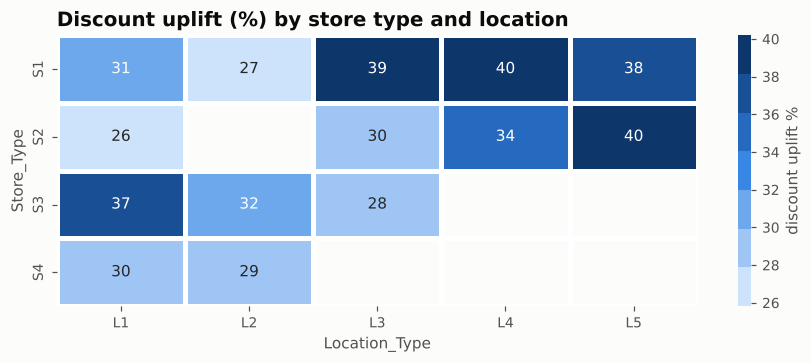

In [21]:
tw = train[train.Sales > 0].assign(log_sales=lambda d: np.log(d.Sales))
for col, h in [("Store_Type", "H8a Discount effect differs by store type"), ("Location_Type", "H8b Discount effect differs by location type")]:
    m = smf.ols(f"log_sales ~ C(Discount) * C({col})", data=tw).fit()
    aov = sm.stats.anova_lm(m, typ=2)
    row = aov.loc[f"C(Discount):C({col})"]
    eta = row["sum_sq"] / aov["sum_sq"].sum()
    record(h, "Two-way ANOVA interaction (log sales)", row["F"], row["PR(>F)"], eta, "partial eta squared", "Reject H0" if row["PR(>F)"] < .05 else "Fail to reject H0")
    display(aov.round(4))
uplift_seg = (tw.groupby(["Store_Type", "Location_Type", "Discount"]).Sales.mean().unstack()
              .pipe(lambda t: (t[1] / t[0] - 1) * 100).unstack())
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.heatmap(uplift_seg, annot=True, fmt=".0f", cmap=sns.color_palette(SEQUENTIAL, as_cmap=True), ax=ax,
            cbar_kws={"label": "discount uplift %"}, linewidths=2, linecolor="white")
ax.set_title("Discount uplift (%) by store type and location"); ax.grid(False)
plt.tight_layout(); save(fig, "12_discount_uplift_segments"); plt.show()

In [22]:
hyp = pd.DataFrame(results)
hyp["p_value_fmt"] = hyp.p_value.map(lambda p: "< 1e-300" if p == 0 else f"{p:.2e}")
hyp.to_csv(PROCESSED_DIR / "hypothesis_results.csv", index=False)
hyp[["hypothesis", "test", "statistic", "p_value_fmt", "effect_size", "effect_measure", "conclusion"]]

,hypothesis,test,statistic,p_value_fmt,effect_size,effect_measure,conclusion
0,H1 Discount affects sales,Welch t-test (store-days),145.929,< 1e-300,0.689,Cohen's d,Reject H0
1,H1 Discount affects sales,Mann-Whitney U (store-days),"6,190,447,035.500",< 1e-300,0.412,rank-biserial r,Reject H0
2,H1 Discount affects sales,Paired t-test (store means),40.828,6.07e-138,33.517,mean uplift %,Reject H0
3,H1 Discount affects sales,Wilcoxon signed-rank (store means),1.000,1.44e-61,99.726,% stores higher,Reject H0
4,H2 Holiday affects sales,Welch t-test (store-days),-66.176,< 1e-300,-0.463,Cohen's d,Reject H0
5,H2 Holiday affects sales,Mann-Whitney U (store-days),"1,478,686,923.500",< 1e-300,-0.271,rank-biserial r,Reject H0
6,H2 Holiday affects sales,Paired t-test (store means),-55.990,5.88e-181,-19.097,mean uplift %,Reject H0
7,H2 Holiday affects sales,Wilcoxon signed-rank (store means),0.000,1.43e-61,0.000,% stores higher,Reject H0
8,H3 Store type affects sales,One-way ANOVA (store-days),"35,123.644",< 1e-300,0.359,eta squared,Reject H0
9,H3 Store type affects sales,Welch ANOVA (store-days),"32,696.207",< 1e-300,0.359,eta squared,Reject H0


> **Insights: hypothesis testing (α = 0.05)**
>
> | # | Hypothesis | Result | Size of the effect |
> |---|---|---|---|
> | H1 | Discounts change sales | **Reject H0** (all four tests, p < 1e-60) | **+33.5% per store** on average; **364 of 365 stores** sell more on discount days; Cohen's d = 0.69 (medium-large) |
> | H2 | Holidays change sales | **Reject H0** | **−19.1% per store**; **every store** sells less on holidays |
> | H3 | Store type matters | **Reject H0** | Store type explains **72%** of the variance between stores (η²); all 6 pairs differ (Tukey) |
> | H4 | Location type matters | **Reject H0** | η² = **0.70** between stores; 8 of 10 pairs differ |
> | H5 | Region matters | **Reject H0, but the effect is small** | η² = **0.03** for store-days; only R1 differs from R2 and R4 |
> | H6 | Weekends sell more | **Reject H0** | **+17.5% per store**; every store |
> | H7 | Orders correlate with sales | **Reject H0** | Pearson r = **0.94** (r² = 0.89), Spearman ρ = 0.94 |
> | H8 | The discount effect depends on segment | **Reject H0, but negligible** | The interaction explains < 0.1% of variance. The uplift is roughly the same everywhere (about 30 to 34%) |
>
> **What this means for the business and for the model:** discounts, holidays, weekdays, store format and location are real, large and consistent effects, so they all go into the model. Region is statistically significant only because the sample is huge, and it matters little in practice. Order count is almost a copy of sales, which is exactly why it must **not** be used as a forecasting input: it is not known in advance.

## 8. Feature engineering

**Rule: a feature is allowed only if it is known on the day the forecast is made.** For a 61-day-ahead forecast that means:

| Group | Features | Why |
|---|---|---|
| Plan inputs | `Holiday`, `Discount` | The holiday calendar and discount plan are set in advance (they are present in the test file) |
| Store identity | `store` (categorical id), `Store_Type`, `Location_Type`, `Region_Code` | Each store has its own level and its own reaction to discounts |
| Calendar | weekday, weekend, month, start/end of month | Weekly and pay-day patterns from the EDA |
| Holiday proximity | days since / until a holiday, holiday yesterday / tomorrow | Demand shifts around holidays, not only on them |
| Campaign context | discount yesterday / tomorrow, consecutive discount days, share of stores on discount that day | Discounts run as chain-wide campaigns; campaign length matters |
| Store level | rolling mean of log sales over 7, 28 and 91 days, **shifted by 61 days** | The latest store level that is actually known 61 days ahead |

**Excluded on purpose:** `#Order`. It is correlated 0.94 with sales but is only known after the day is over, so using it would leak the target. (It is useful for a *same-day nowcast*, but not for a forecast.)

**Target transform:** the model learns `log(1 + Sales)`. This turns multiplicative effects (a discount adds ~a percentage, not a fixed amount) into additive ones and makes the error relative, so small stores matter as much as big ones. **Zero-sales days** (19 store closures) are dropped from training and masked out of the rolling features.

In [23]:
t0 = time.time()
feat = build_features(train.drop(columns=["AOV", "is_weekend"]))
print(f"Feature matrix built in {time.time()-t0:.1f}s: {feat.shape[0]:,} rows, {len(FEATURES)} model features")
feat[["Store_id", "Date", "Sales"] + FEATURES].sample(5, random_state=3)

Feature matrix built in 0.7s: 188,340 rows, 22 model features


,Store_id,Date,Sales,Holiday,Discount,store,Store_Type,Location_Type,Region_Code,dayofweek,is_weekend,month,is_month_start,is_month_end,days_since_holiday,days_to_holiday,holiday_prev_day,holiday_next_day,discount_prev_day,discount_next_day,discount_share_day,discount_streak,roll_mean_7,roll_mean_28,roll_mean_91
27814,54,2019-04-12,"30,549.000",0,0,54,S1,L2,R3,4,0,4,0,0,6,1,0,1,0,0,0.033,0,10.683,10.647,10.676
11812,23,2019-04-06,"32,859.720",1,1,23,S1,L1,R4,5,1,4,0,0,0,0,0,0,1,1,0.929,3,10.415,10.412,10.437
47061,92,2018-04-16,"24,000.000",0,0,92,S1,L4,R2,0,0,4,0,0,1,14,1,0,0,0,0.008,0,10.089,10.055,10.163
475,1,2019-04-21,"48,954.450",1,1,1,S1,L3,R1,6,1,4,0,0,0,0,0,0,1,1,0.151,4,10.296,10.394,10.442
143926,279,2019-04-24,"21,771.000",0,0,279,S2,L3,R2,2,0,4,0,0,3,15,0,0,0,0,0.038,0,10.052,10.138,10.248


## 9. Validation design

A random train/test split would leak the future into the past. Instead the models are validated with **rolling-origin (expanding window) cross-validation**: each fold trains on everything before a cut-off date and forecasts the next **61 days**, exactly the length of the real forecast. Three folds cover December 2018 to May 2019, so the scores average over different seasons, holiday periods and campaign patterns.

```
fold 1: train 2018-01-01 .. 2018-11-30 | forecast 2018-12-01 .. 2019-01-30
fold 2: train 2018-01-01 .. 2019-01-31 | forecast 2019-02-01 .. 2019-04-02
fold 3: train 2018-01-01 .. 2019-03-31 | forecast 2019-04-01 .. 2019-05-31   <- final hold-out
```

In [24]:
CUTOFFS = [pd.Timestamp("2018-12-01"), pd.Timestamp("2019-02-01"), pd.Timestamp("2019-04-01")]
def folds():
    for c in CUTOFFS:
        trn = feat[feat.Date < c]
        val = feat[(feat.Date >= c) & (feat.Date < c + pd.Timedelta(days=HORIZON))]
        yield c, training_rows(trn), val

def cv_score(name, fit_predict):
    rows, store_day_preds = [], []
    t0 = time.time()
    for c, trn, val in folds():
        pred = np.clip(fit_predict(trn, val), 0, None)
        r = evaluate(val.Sales, pred, name); r["fold"] = str(c.date())
        agg = val.assign(p=pred).groupby("Date")[["Sales", "p"]].sum()
        r["chain_day_WAPE_%"] = evaluate(agg.Sales, agg.p)["WAPE_%"]
        rows.append(r); store_day_preds.append(val[["Store_id", "Date", "Sales"]].assign(pred=pred, fold=str(c.date())))
    out = pd.DataFrame(rows)
    summary = out.drop(columns="fold").groupby("model").mean()
    summary["fit_time_s"] = (time.time() - t0) / len(CUTOFFS)
    return summary, out, pd.concat(store_day_preds)

leaderboard, fold_scores, cv_preds = [], [], {}
def run(name, fn):
    s, f, p = cv_score(name, fn)
    leaderboard.append(s); fold_scores.append(f); cv_preds[name] = p
    display(s.round(2))

## 10. Modelling

### 10.1 Baselines
A model is only useful if it beats simple rules a planner could apply in a spreadsheet:
* **Store average**: each store's mean daily sales over the last 91 known days.
* **Seasonal naive**: each store's mean for the same weekday over its whole history.
* **Seasonal naive + discount/holiday multipliers**: the weekday mean, scaled by the store's own historical discount and holiday ratios. This is the strongest "spreadsheet" rule.

In [25]:
def store_average(trn, val):
    recent = trn[trn.Date >= trn.Date.max() - pd.Timedelta(days=90)]
    return val.Store_id.map(recent.groupby("Store_id").Sales.mean()).values

def seasonal_naive(trn, val):
    m = trn.groupby(["Store_id", "dayofweek"]).Sales.mean()
    return pd.MultiIndex.from_frame(val[["Store_id", "dayofweek"]]).map(m).values

def seasonal_naive_mult(trn, val):
    base_rows = trn[(trn.Discount == 0) & (trn.Holiday == 0)]
    m = base_rows.groupby(["Store_id", "dayofweek"]).Sales.mean()
    base = pd.MultiIndex.from_frame(val[["Store_id", "dayofweek"]]).map(m).values
    d = trn.groupby(["Store_id", "Discount"]).Sales.mean().unstack(); d_mult = (d[1] / d[0])
    h = trn.groupby(["Store_id", "Holiday"]).Sales.mean().unstack(); h_mult = (h[1] / h[0])
    return base * np.where(val.Discount == 1, val.Store_id.map(d_mult), 1) * np.where(val.Holiday == 1, val.Store_id.map(h_mult), 1)

run("Baseline: store 91-day average", store_average)
run("Baseline: seasonal naive (weekday mean)", seasonal_naive)
run("Baseline: weekday mean x discount/holiday ratio", seasonal_naive_mult)

,MAE,RMSE,MAPE_%,WAPE_%,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
Baseline: store 91-day average,"10,349.430","14,485.890",30.970,23.580,0.440,17.020,0.150


,MAE,RMSE,MAPE_%,WAPE_%,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
Baseline: seasonal naive (weekday mean),"10,002.300","13,894.290",30.510,22.780,0.490,15.020,0.140


,MAE,RMSE,MAPE_%,WAPE_%,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
Baseline: weekday mean x discount/holiday ratio,"8,212.680","11,887.200",23.580,18.710,0.620,12.390,0.190


### 10.2 Machine-learning models
All ML models use the same feature set and the same log target, so the comparison is about the algorithm only.
* **Linear regression** (Ridge, one-hot encoded categoricals, standardised numerics): the interpretable baseline the brief asks for.
* **Random forest**: bagged trees, captures non-linearities and interactions.
* **XGBoost** and **LightGBM**: gradient-boosted trees, the state of the art for tabular forecasting.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import lightgbm as lgb

CAT = ["store", "Store_Type", "Location_Type", "Region_Code", "dayofweek", "month"]
NUM = [f for f in FEATURES if f not in CAT]

def linear(trn, val):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
                             ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM)])
    m = make_pipeline(pre, Ridge(alpha=1.0)).fit(trn[FEATURES].astype({c: str for c in CAT}), np.log1p(trn.Sales))
    return np.expm1(m.predict(val[FEATURES].astype({c: str for c in CAT})))

def to_numeric(df):
    X = df[FEATURES].copy()
    for c in X.select_dtypes("category"): X[c] = X[c].cat.codes
    return X

def random_forest(trn, val):
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=42)
    m.fit(to_numeric(trn).fillna(-1), np.log1p(trn.Sales))
    return np.expm1(m.predict(to_numeric(val).fillna(-1)))

def xgboost(trn, val):
    m = xgb.XGBRegressor(n_estimators=1500, learning_rate=0.03, max_depth=8, subsample=0.8, colsample_bytree=0.8,
                         min_child_weight=20, tree_method="hist", enable_categorical=True, max_cat_to_onehot=1, n_jobs=-1, random_state=42)
    m.fit(trn[FEATURES], np.log1p(trn.Sales))
    return np.expm1(m.predict(val[FEATURES]))

def lightgbm(trn, val, features=FEATURES, params=LGBM_PARAMS):
    m = lgb.LGBMRegressor(**params).fit(trn[features], np.log1p(trn.Sales))
    return np.expm1(m.predict(val[features]))

run("Linear regression (Ridge)", linear)
run("Random forest", random_forest)
run("XGBoost", xgboost)
run("LightGBM", lightgbm)

,MAE,RMSE,MAPE_%,WAPE_%,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
Linear regression (Ridge),"8,309.480","11,849.180",22.430,18.930,0.630,12.570,2.460


,MAE,RMSE,MAPE_%,WAPE_%,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
Random forest,"8,097.310","11,643.940",20.800,18.400,0.640,13.490,33.040


,MAE,RMSE,MAPE_%,WAPE_%,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
XGBoost,"6,779.850","10,060.350",17.420,15.380,0.730,10.370,38.270


,MAE,RMSE,MAPE_%,WAPE_%,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
LightGBM,"6,745.630","10,007.660",17.440,15.300,0.730,10.420,16.540


### 10.3 Ablation: why the final feature set looks the way it does
A common reflex is to add many raw lags (sales 63, 70, 77... days ago) and day-of-year terms. With only 17 months of history these features are noisy, and the cross-validation shows they make the model *worse*. Removing the store identity also hurts, which tells us each store has a persistent level and discount response that the attributes alone don't capture.

In [27]:
run("LightGBM + raw lags & day-of-year (rejected)", lambda t, v: lightgbm(t, v, FEATURES + ABLATION_FEATURES))
run("LightGBM without store id (rejected)", lambda t, v: lightgbm(t, v, [f for f in FEATURES if f != "store"]))
run("LightGBM without discount context (rejected)", lambda t, v: lightgbm(t, v, [f for f in FEATURES if not f.startswith("discount_")]))

,MAE,RMSE,MAPE_%,WAPE_%,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
LightGBM + raw lags & day-of-year (rejected),"6,976.330","10,491.810",19.430,15.860,0.710,10.960,24.140


,MAE,RMSE,MAPE_%,WAPE_%,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
LightGBM without store id (rejected),"8,176.210","11,664.100",20.900,18.560,0.640,13.460,14.460


,MAE,RMSE,MAPE_%,WAPE_%,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
LightGBM without discount context (rejected),"7,964.600","11,427.970",20.540,18.120,0.650,11.670,16.200


### 10.4 Statistical time-series models (chain level)
Classical models (SARIMA, Holt-Winters, Prophet) forecast one series at a time. Fitting 365 of them would ignore what stores share, so they are compared where they are strongest: the **total chain sales per day**. The LightGBM store-level forecasts are summed to the same level for a like-for-like comparison. SARIMAX and Prophet get the discount share and holiday flag as external regressors, so they have the same planning information as LightGBM.

,MAE,RMSE,MAPE_%,WAPE_%,R2
model,,,,,
LightGBM (sum of 365 store forecasts),"1,688,331.590","2,205,076.730",12.330,10.420,0.510
"SARIMAX(1,0,1)(1,0,1)7 + discount, holiday","2,288,555.350","3,062,693.230",17.500,14.210,0.050
"Prophet + discount, holiday","2,731,109.610","3,312,606.160",20.580,17.190,-0.160
"Holt-Winters (damped, weekly)","2,922,097.600","3,699,141.520",22.190,18.070,-0.400


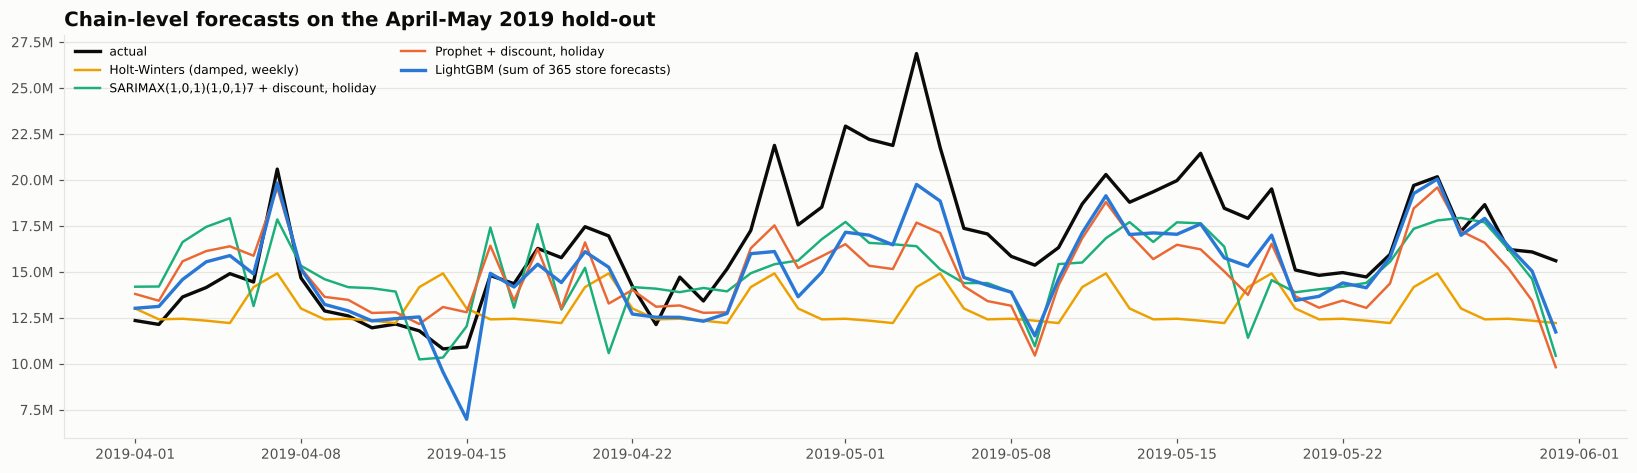

In [28]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from prophet import Prophet
import logging; logging.getLogger("cmdstanpy").disabled = True
warnings.filterwarnings("ignore")

chain = feat.groupby("Date").agg(Sales=("Sales", "sum"), disc=("Discount", "mean"), hol=("Holiday", "max")).asfreq("D")
chain_rows = []
chain_preds = {}
for c in CUTOFFS:
    trn, val = chain[chain.index < c], chain[(chain.index >= c) & (chain.index < c + pd.Timedelta(days=HORIZON))]
    preds = {}
    hw = ExponentialSmoothing(trn.Sales, trend="add", damped_trend=True, seasonal="mul", seasonal_periods=7).fit()
    preds["Holt-Winters (damped, weekly)"] = hw.forecast(len(val)).values
    sar = SARIMAX(np.log(trn.Sales), exog=trn[["disc", "hol"]], order=(1, 0, 1), seasonal_order=(1, 0, 1, 7), trend="c").fit(disp=False)
    preds["SARIMAX(1,0,1)(1,0,1)7 + discount, holiday"] = np.exp(sar.forecast(len(val), exog=val[["disc", "hol"]]).values)
    pdf = trn.reset_index().rename(columns={"Date": "ds", "Sales": "y"})
    pm = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False, seasonality_mode="multiplicative")
    pm.add_regressor("disc"); pm.add_regressor("hol"); pm.fit(pdf)
    preds["Prophet + discount, holiday"] = pm.predict(val.reset_index().rename(columns={"Date": "ds"}))["yhat"].values
    lg = cv_preds["LightGBM"]; lg = lg[lg.fold == str(c.date())].groupby("Date").pred.sum().reindex(val.index).values
    preds["LightGBM (sum of 365 store forecasts)"] = lg
    for name, p in preds.items():
        r = evaluate(val.Sales, p, name); r["fold"] = str(c.date()); chain_rows.append(r)
    chain_preds[c] = (val, preds)
chain_board = pd.DataFrame(chain_rows).drop(columns="fold").groupby("model").mean().sort_values("WAPE_%")
display(chain_board.round(2))

val, preds = chain_preds[CUTOFFS[-1]]
fig, ax = plt.subplots(figsize=(15, 4.4))
ax.plot(val.index, val.Sales, color="#0b0b0b", lw=2.2, label="actual")
for (name, p), col in zip(preds.items(), [YELLOW, AQUA, ORANGE, BLUE]):
    ax.plot(val.index, p, lw=1.6 if "LightGBM" not in name else 2.2, color=col, label=name)
ax.yaxis.set_major_formatter(money); ax.legend(ncol=2, fontsize=8, loc="upper left")
ax.set_title("Chain-level forecasts on the April-May 2019 hold-out")
plt.tight_layout(); save(fig, "13_chain_model_comparison"); plt.show()

**About LSTMs.** The brief lists LSTMs as an option. They were deliberately not used: there are only 516 days per store, the strongest signals are planned events (discounts, holidays) rather than long sequential memory, and gradient-boosted trees are consistently stronger than LSTMs on short tabular panels like this one (see the M5 competition results). An LSTM would add training cost and opacity without a realistic accuracy gain, so the effort went into validation and features instead, as the brief allows ("analyses that do not yield useful insights can be skipped").

,WAPE_%,MAPE_%,MAE,RMSE,R2,chain_day_WAPE_%,fit_time_s
model,,,,,,,
LightGBM,15.30,17.44,6745.63,10007.66,0.73,10.42,16.54
XGBoost,15.38,17.42,6779.85,10060.35,0.73,10.37,38.27
LightGBM + raw lags & day-of-year (rejected),15.86,19.43,6976.33,10491.81,0.71,10.96,24.14
LightGBM without discount context (rejected),18.12,20.54,7964.60,11427.97,0.65,11.67,16.20
Random forest,18.40,20.80,8097.31,11643.94,0.64,13.49,33.04
LightGBM without store id (rejected),18.56,20.90,8176.21,11664.10,0.64,13.46,14.46
Baseline: weekday mean x discount/holiday ratio,18.71,23.58,8212.68,11887.20,0.62,12.39,0.19
Linear regression (Ridge),18.93,22.43,8309.48,11849.18,0.63,12.57,2.46
Baseline: seasonal naive (weekday mean),22.78,30.51,10002.30,13894.29,0.49,15.02,0.14


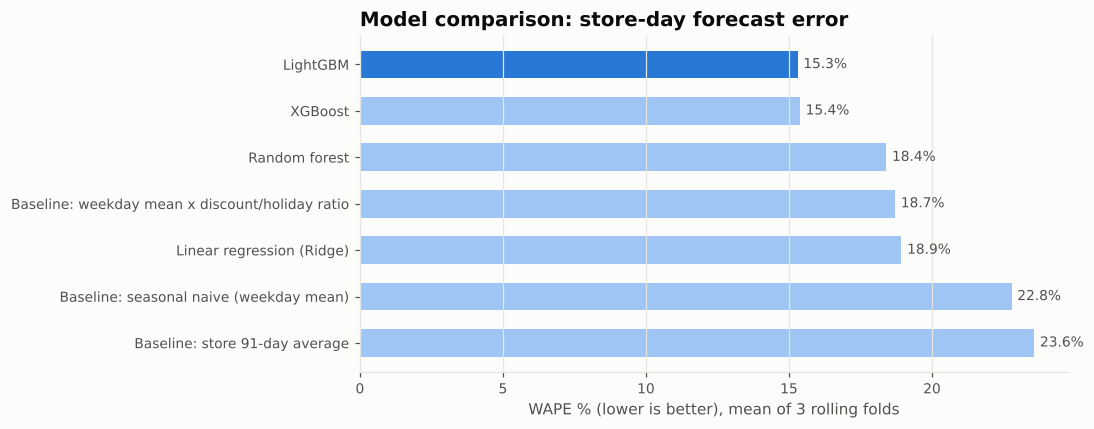

In [29]:
board = pd.concat(leaderboard).sort_values("WAPE_%")
board.to_csv(PROCESSED_DIR / "model_comparison.csv")
pd.concat(fold_scores).to_csv(PROCESSED_DIR / "model_comparison_by_fold.csv", index=False)
chain_board.to_csv(PROCESSED_DIR / "chain_model_comparison.csv")
display(board[["WAPE_%", "MAPE_%", "MAE", "RMSE", "R2", "chain_day_WAPE_%", "fit_time_s"]].round(2)
        .style.highlight_min(subset=["WAPE_%", "MAPE_%", "MAE", "RMSE"], color="#cde2fb")
        .highlight_max(subset=["R2"], color="#cde2fb").format(precision=2))

plot_board = board[~board.index.str.contains("rejected")].sort_values("WAPE_%", ascending=True)
fig, ax = plt.subplots(figsize=(10, 4))
colors = [BLUE if "LightGBM" == n else SEQUENTIAL[1] for n in plot_board.index]
ax.barh(plot_board.index[::-1], plot_board["WAPE_%"][::-1], color=colors[::-1], height=0.6)
for i, v in enumerate(plot_board["WAPE_%"][::-1]): ax.text(v + .2, i, f"{v:.1f}%", va="center", color=INK_2, fontsize=9)
ax.set_xlabel("WAPE % (lower is better), mean of 3 rolling folds"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Model comparison: store-day forecast error")
plt.tight_layout(); save(fig, "14_model_leaderboard"); plt.show()

> **Insights: model comparison (mean of 3 rolling 61-day folds)**
> * **Gradient boosting wins clearly.** LightGBM (**WAPE 15.3%, R² 0.73**) and XGBoost (15.4%) cut the error by **a third** compared with the naive weekday baseline (22.8%), and by **18%** compared with the strongest spreadsheet rule (weekday mean × the store's own discount and holiday ratios, 18.7%).
> * **Linear regression (18.9%) and random forest (18.4%) barely beat the strongest rule.** The problem needs interactions (for example, a store's discount response on a weekend just after a holiday) that boosting captures best.
> * **LightGBM is selected** over XGBoost: the accuracy is the same, but LightGBM trains more than twice as fast (17s vs 38s per fold), handles the 365-level store category natively, and the model file is small enough for a free cloud app.
> * **The ablations justify the feature design.** Adding raw lags and day-of-year makes the model *worse* (15.9%), so they were removed. Removing the store identity (18.6%) or the campaign-context features (18.1%) costs about 3 points each.
> * **At chain level, LightGBM (sum of 365 store forecasts) beats every classical model**: WAPE **10.4%** vs SARIMAX 14.2%, Prophet 17.2% and Holt-Winters 18.1%. This holds even though SARIMAX and Prophet were given the same discount and holiday information. Pooling the 365 stores gives the model about 365 times more examples of each event.

## 11. Hyper-parameter tuning
A compact random search over the LightGBM parameters that matter most, scored on the same three rolling folds. The best setting is compared with the defaults used so far.

In [30]:
rng = np.random.default_rng(7)
space = dict(num_leaves=[31, 63, 127], min_child_samples=[20, 40, 100], learning_rate=[0.02, 0.03, 0.05],
             colsample_bytree=[0.6, 0.8, 1.0], reg_lambda=[0, 1, 5])
trials = []
for i in range(8):
    p = {k: rng.choice(v).item() for k, v in space.items()}
    params = dict(LGBM_PARAMS, **p, n_estimators=int(45 / p["learning_rate"]))
    s, _, _ = cv_score(f"trial {i}", lambda t, v: lightgbm(t, v, params=params))
    trials.append({**p, "n_estimators": params["n_estimators"], **s.iloc[0][["WAPE_%", "MAPE_%", "RMSE", "R2"]].to_dict()})
tuning = pd.DataFrame(trials).sort_values("WAPE_%")
tuning.to_csv(PROCESSED_DIR / "tuning_trials.csv", index=False)
default = board.loc["LightGBM", ["WAPE_%", "MAPE_%", "RMSE", "R2"]]
print(f"Default params: WAPE {default['WAPE_%']:.2f}%, RMSE {default['RMSE']:,.0f}")
tuning.round(3)

Default params: WAPE 15.30%, RMSE 10,008


,num_leaves,min_child_samples,learning_rate,colsample_bytree,reg_lambda,n_estimators,WAPE_%,MAPE_%,RMSE,R2
6,63,40,0.030,1.000,5,1500,15.395,17.752,"10,089.019",0.730
5,31,100,0.030,0.800,1,1500,15.443,17.475,"10,105.066",0.729
0,127,40,0.050,1.000,1,900,15.576,17.918,"10,189.738",0.725
2,31,100,0.050,0.600,1,900,15.595,17.582,"10,150.005",0.727
7,127,100,0.030,0.800,5,1500,15.602,17.714,"10,172.954",0.726
3,127,20,0.050,0.600,1,900,15.726,17.849,"10,207.705",0.724
1,127,100,0.020,0.600,0,2250,15.787,17.743,"10,231.757",0.722
4,127,20,0.030,0.600,5,1500,15.807,17.972,"10,242.255",0.722


> **Insights: tuning.** None of the 8 random configurations beat the default parameters (WAPE 15.30%). The best trial scored 15.40%, and the whole range was only 15.4 to 15.8%. The model is **not sensitive to tuning**: the gains came from features and validation design, not from hyper-parameters. The defaults (63 leaves, learning rate 0.03, 1,500 trees, 80% row and column sampling) are kept.

## 12. Final evaluation on the hold-out (April to May 2019)
The production model is trained on data up to 31 March 2019 and forecasts 1 April to 31 May 2019 through the **same code path the app uses** (`SalesForecaster.forecast`), so this is the honest out-of-sample score that the README reports.

In [31]:
cut = CUTOFFS[-1]
hist, hold = train[train.Date < cut], train[train.Date >= cut]
fc = SalesForecaster().fit(hist.drop(columns=["AOV", "is_weekend"]))
val = fc.forecast(hist, hold.drop(columns=["Sales", "Orders", "AOV", "is_weekend"])).merge(hold[["Store_id", "Date", "Sales"]])
final_scores = pd.DataFrame([evaluate(val.Sales, val.Forecast, "Store x day"),
                             evaluate(*val.groupby("Date")[["Sales", "Forecast"]].sum().T.values, "Chain x day"),
                             evaluate(*val.groupby("Store_id")[["Sales", "Forecast"]].sum().T.values, "Store x 61-day total"),
                             evaluate(*val.groupby([val.Store_id, val.Date.dt.isocalendar().week])[["Sales", "Forecast"]].sum().T.values, "Store x week")]).set_index("model")
final_scores.round(3)

,MAE,RMSE,MAPE_%,WAPE_%,R2
model,,,,,
Store x day,"7,636.043","12,208.481",15.589,16.808,0.669
Chain x day,"1,928,195.472","2,529,097.110",11.029,11.628,0.424
Store x 61-day total,"290,574.831","379,669.957",9.897,10.485,0.828
Store x week,"40,786.057","65,417.346",11.469,13.246,0.728


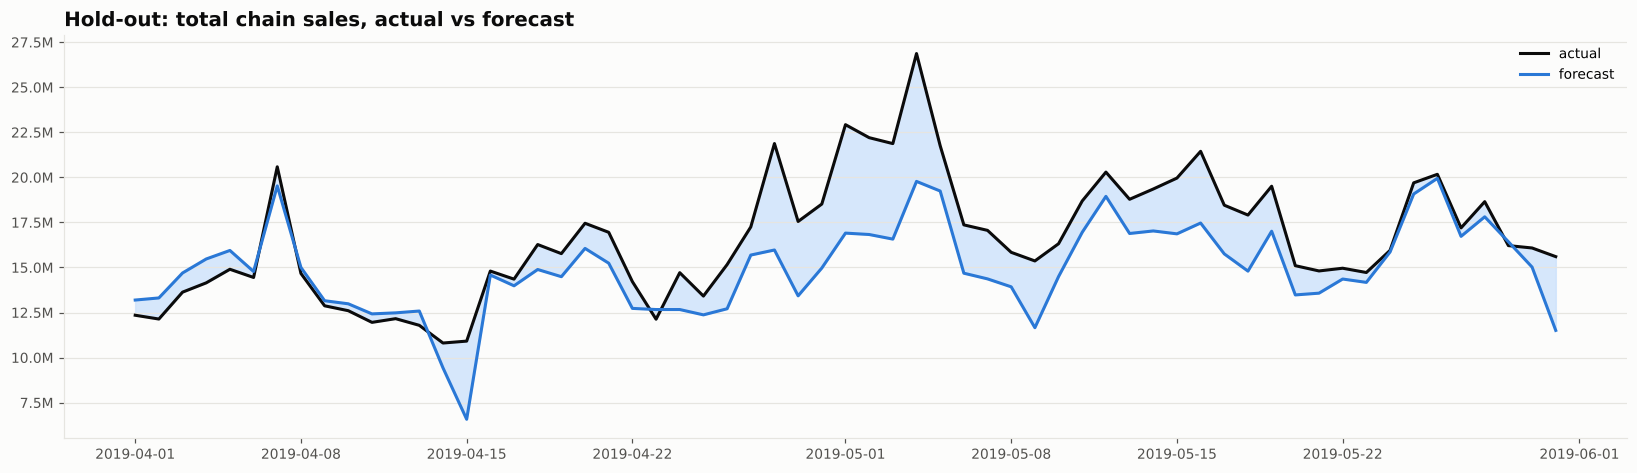

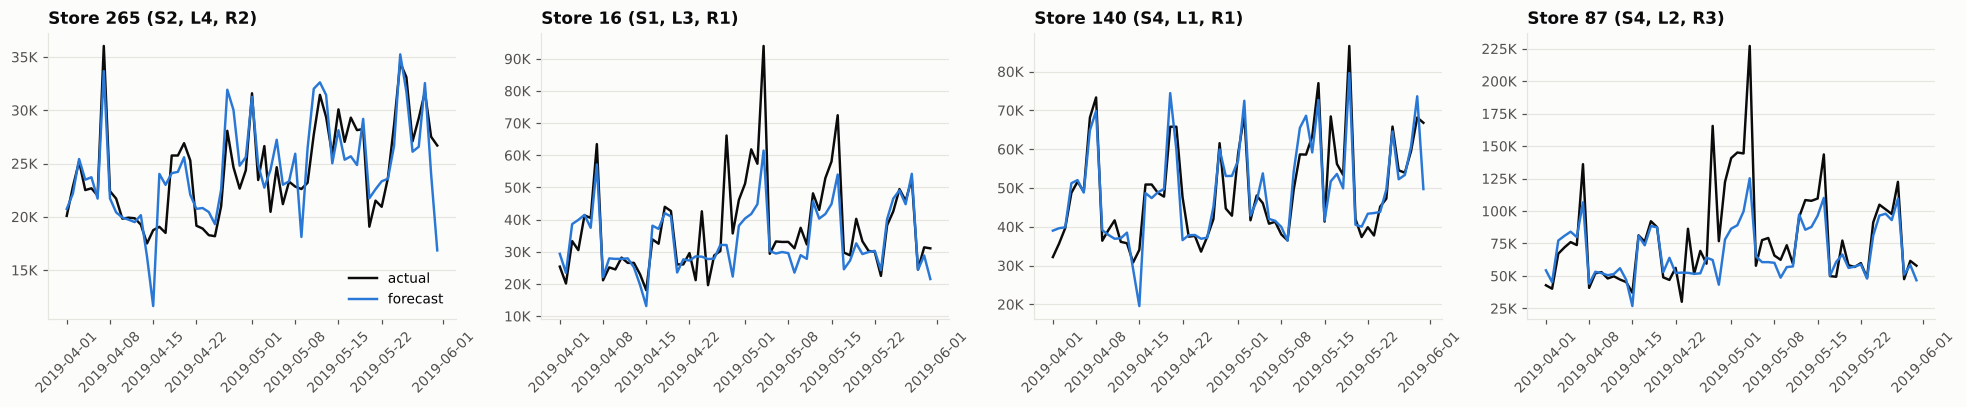

In [32]:
d = val.groupby("Date")[["Sales", "Forecast"]].sum()
fig, ax = plt.subplots(figsize=(15, 4.4))
ax.plot(d.index, d.Sales, color="#0b0b0b", lw=2, label="actual")
ax.plot(d.index, d.Forecast, color=BLUE, lw=2, label="forecast")
ax.fill_between(d.index, d.Sales, d.Forecast, color=SEQUENTIAL[0], alpha=.8)
ax.yaxis.set_major_formatter(money); ax.legend(); ax.set_title("Hold-out: total chain sales, actual vs forecast")
plt.tight_layout(); save(fig, "15_holdout_actual_vs_forecast"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, sid in zip(axes, val.groupby("Store_id").Sales.mean().sort_values().index[[10, 120, 240, 355]]):
    s = val[val.Store_id == sid]
    ax.plot(s.Date, s.Sales, color="#0b0b0b", lw=1.6, label="actual"); ax.plot(s.Date, s.Forecast, color=BLUE, lw=1.6, label="forecast")
    st = s.iloc[0]; ax.set_title(f"Store {sid} ({st.Store_Type}, {st.Location_Type}, {st.Region_Code})", fontsize=11)
    ax.yaxis.set_major_formatter(money); ax.tick_params(axis="x", rotation=45)
axes[0].legend()
plt.tight_layout(); save(fig, "16_holdout_store_examples"); plt.show()

Store_Type                        Location_Type                        \
               S1     S2      S3      S4            L1      L2     L3     L4   
WAPE_%     15.800 15.800  17.600  17.940        15.980  17.850 17.100 14.400   
bias_%     -9.010 -6.910 -10.870 -11.140        -9.240 -10.750 -9.930 -8.030   

              Region_Code                       Discount        Holiday  \
           L5          R1     R2      R3     R4        0      1       0   
WAPE_% 17.660      17.920 15.100  17.130 16.450   18.090 15.490  16.380   
bias_% -9.350     -11.490 -7.450 -10.200 -9.090  -10.010 -9.640  -9.280   

                
             1  
WAPE_%  19.390  
bias_% -13.110

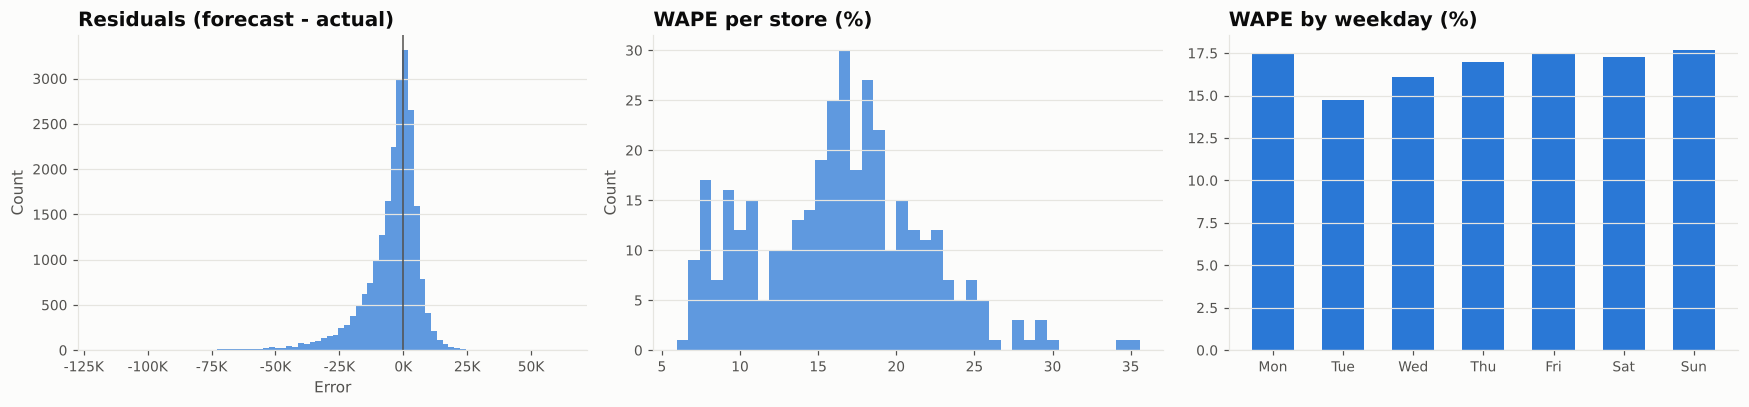

Median store WAPE 16.5% | 90% of stores below 22.9% | overall bias -9.83%


In [33]:
val["APE"] = (val.Forecast - val.Sales).abs() / val.Sales.replace(0, np.nan)
val["Error"] = val.Forecast - val.Sales
seg_err = pd.concat({c: val.groupby(c).apply(lambda g: pd.Series({
            "WAPE_%": 100 * g.Error.abs().sum() / g.Sales.sum(), "bias_%": 100 * g.Error.sum() / g.Sales.sum()}))
            for c in ["Store_Type", "Location_Type", "Region_Code", "Discount", "Holiday"]})
display(seg_err.round(2).T)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(val.Error, bins=80, ax=axes[0], color=BLUE, edgecolor="none"); axes[0].axvline(0, color=INK_2, lw=1)
axes[0].xaxis.set_major_formatter(money); axes[0].set_title("Residuals (forecast - actual)")
store_wape = val.groupby("Store_id").apply(lambda g: 100 * g.Error.abs().sum() / g.Sales.sum())
sns.histplot(store_wape, bins=40, ax=axes[1], color=BLUE, edgecolor="none"); axes[1].set_title("WAPE per store (%)")
dow_err = val.groupby(val.Date.dt.day_name().str[:3], sort=False).apply(lambda g: 100 * g.Error.abs().sum() / g.Sales.sum())
axes[2].bar(dow_err.index, dow_err.values, color=BLUE, width=0.6); axes[2].set_title("WAPE by weekday (%)")
plt.tight_layout(); save(fig, "17_error_analysis"); plt.show()
print(f"Median store WAPE {store_wape.median():.1f}% | 90% of stores below {store_wape.quantile(.9):.1f}% | overall bias {100*val.Error.sum()/val.Sales.sum():+.2f}%")

> **Insights: hold-out performance (1 Apr to 31 May 2019, 61 days ahead)**
>
> | Level | WAPE | MAPE | R² |
> |---|---|---|---|
> | Store × day | **16.8%** | 15.6% | 0.67 |
> | Store × week | 13.2% | 11.5% | 0.73 |
> | Store × 61-day total | **10.5%** | 9.9% | **0.83** |
> | Chain × day | 11.6% | 11.0% | 0.42 |
>
> * Errors shrink as forecasts are aggregated. For **inventory and budget planning at store-month level the forecast is about 90% accurate**. Single store-days remain noisy (16.8%), because daily sales carry randomness that no calendar can predict.
> * The forecast **tracks the shape of the chain curve closely** (campaign peaks, holiday dips, weekends), but it **under-forecasts this hold-out by 9.8%**. **May 2019 was a record month (+10% on May 2018)** and is above anything in the training history. The bias is not systematic: across the earlier folds it ranged from −10.5% to +4.5%, so applying a fixed correction factor was tested and rejected. The practical remedy is to **retrain monthly** so the model picks up level shifts quickly.
> * The error is **even across segments** (WAPE 14 to 18% for every store type, location and region). There is no blind spot. Accuracy is lowest on **holidays (19.4%)**, the rarest event in the data.
> * **The median store has 16.5% WAPE, and 90% of stores are below 22.9%.**

## 13. Explainability: what drives the forecast

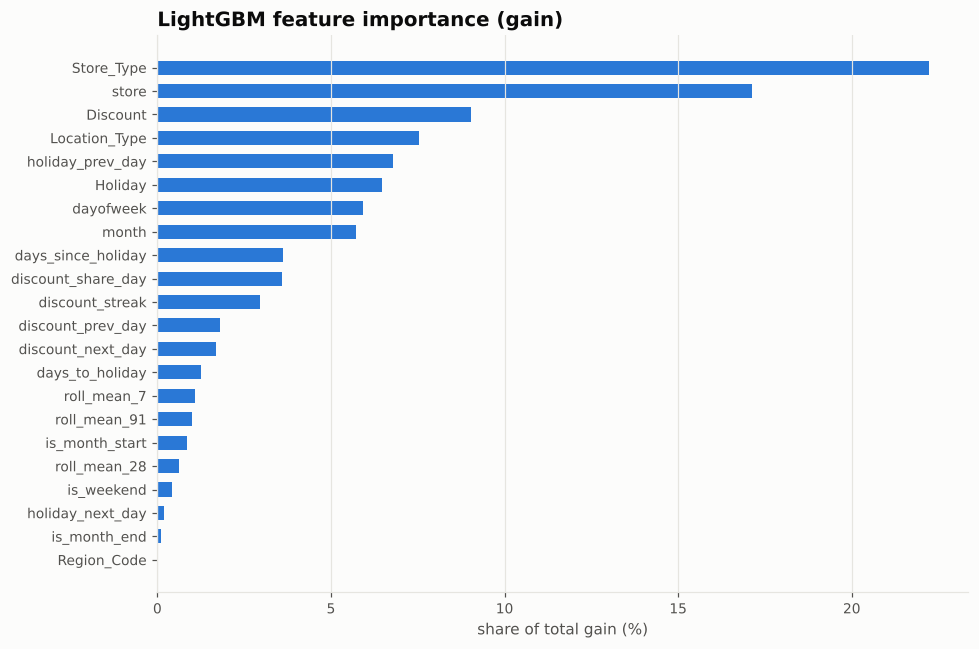

In [34]:
imp = pd.Series(fc.model.booster_.feature_importance("gain"), index=fc.features)
imp = (100 * imp / imp.sum()).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("share of total gain (%)"); ax.set_title("LightGBM feature importance (gain)")
plt.tight_layout(); save(fig, "18_feature_importance"); plt.show()

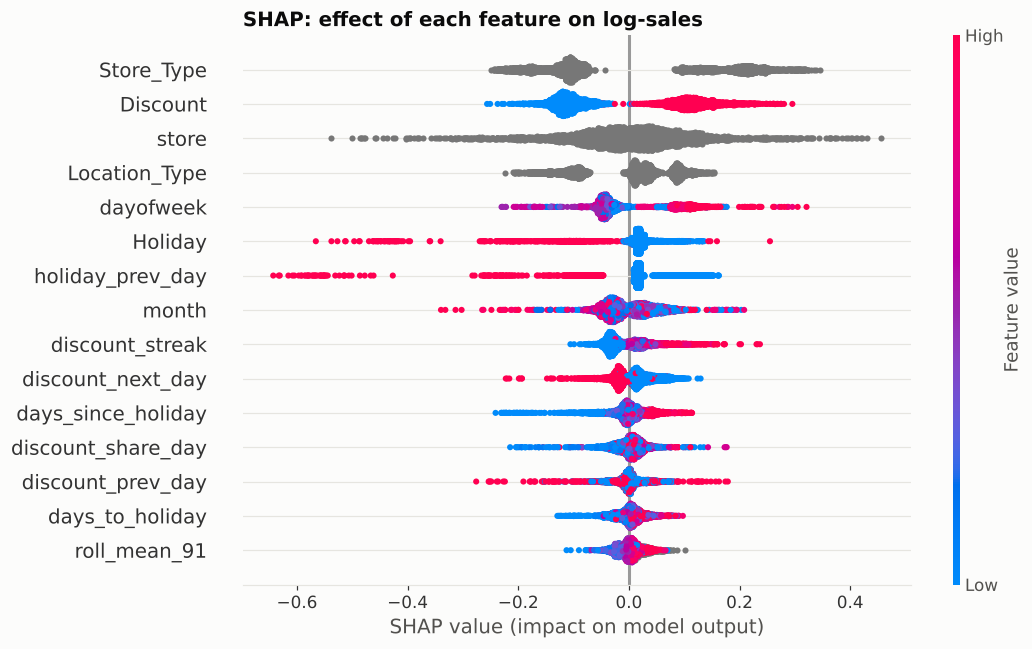

Model-implied discount effect: +25.7% | holiday effect: -15.4% (holding other features fixed)


In [35]:
import shap
sample = build_features(hist.drop(columns=["AOV", "is_weekend"])).pipe(training_rows).sample(4000, random_state=0)
explainer = shap.TreeExplainer(fc.model)
sv = explainer.shap_values(sample[fc.features])
shap.summary_plot(sv, sample[fc.features], show=False, max_display=15, plot_size=(10, 6))
plt.title("SHAP: effect of each feature on log-sales", loc="left"); plt.tight_layout()
save(plt.gcf(), "19_shap_summary"); plt.show()
eff = pd.DataFrame({"Discount": sample.Discount.values, "shap": sv[:, fc.features.index("Discount")]}).groupby("Discount").shap.mean()
hol = pd.DataFrame({"Holiday": sample.Holiday.values, "shap": sv[:, fc.features.index("Holiday")]}).groupby("Holiday").shap.mean()
print(f"Model-implied discount effect: {np.exp(eff[1]-eff[0])-1:+.1%} | holiday effect: {np.exp(hol[1]-hol[0])-1:+.1%} (holding other features fixed)")

> **Insights: what drives the forecast**
> * **Store format, the store itself and location** set the base level. This matches the ANOVA results (η² ≈ 0.7).
> * **Discount is the strongest controllable lever.** Holding everything else fixed, the model attributes **+25.7%** to a discount day. That is lower than the raw +33% because part of the raw gap comes from campaigns falling on strong days.
> * **Holidays are the strongest negative driver** (−15% holding everything else fixed). The SHAP plot shows a deeper effect on **consecutive holiday days**: in the raw data, the first day of a holiday is −9% versus a normal day, but **the second and later days of a multi-day holiday are −48%**.
> * **Campaign dynamics matter**: sales rise the longer a campaign runs (`discount_streak`), and the **day before a campaign starts** is weaker for many stores, as customers wait for the discount. This is store-specific: for a quarter of stores the pre-campaign day is 16% or more below a normal day.
> * **Weekday** and **month** add the weekly rhythm and seasonal peaks. Rolling store levels make small corrections.

## 14. Final forecast: June and July 2019
The model is retrained on all 516 days and forecasts the 22,265 store-days in `TEST_FINAL.csv`, using the holiday calendar and discount plan given there. `scripts/train.py` runs the same steps and writes the model file the app and API load, plus `data/processed/test_forecast.csv`.

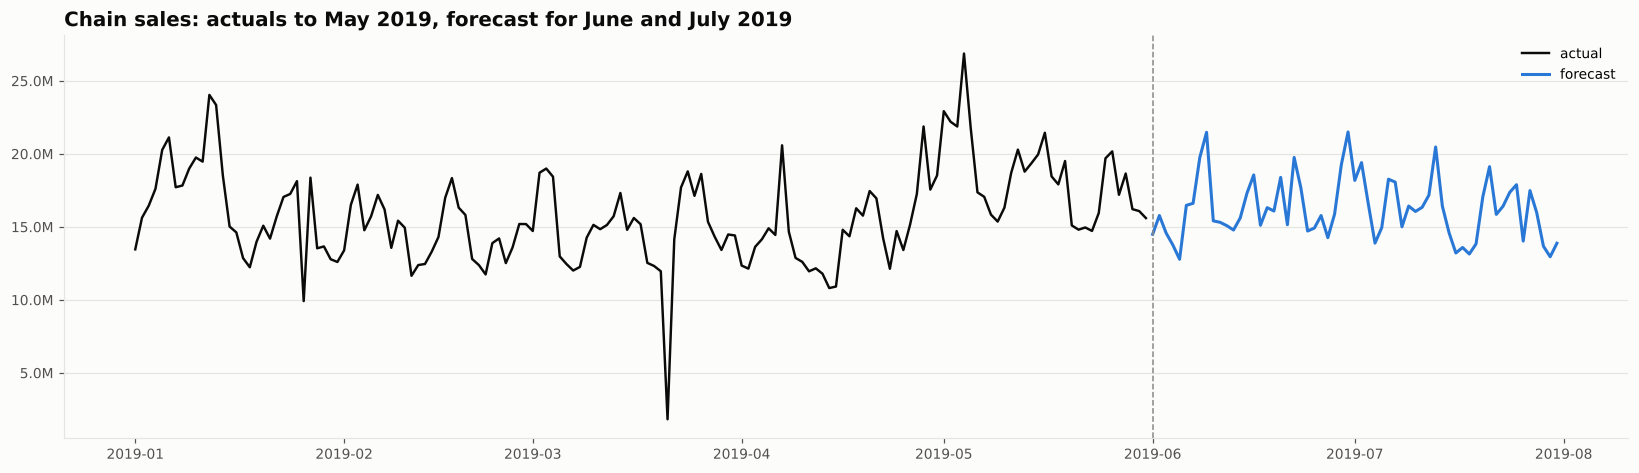

,total sales,vs forecast
forecast Jun-Jul 2019,"989,801,847",+0.0%
actual Jun-Jul 2018,"1,016,641,575",+2.7%
actual Apr-May 2019,"1,011,518,030",+2.2%


Forecast by store type (total, Jun-Jul 2019):


Store_Type,S1,S2,S3,S4
sales (M),409.400,97.200,143.100,340.100


In [36]:
final = SalesForecaster().fit(train.drop(columns=["AOV", "is_weekend"]))
forecast = final.forecast(train, test)
fd = forecast.groupby("Date").Forecast.sum()
fig, ax = plt.subplots(figsize=(15, 4.4))
recent = daily.Sales[daily.index >= "2019-01-01"]
ax.plot(recent.index, recent.values, color="#0b0b0b", lw=1.6, label="actual")
ax.plot(fd.index, fd.values, color=BLUE, lw=2, label="forecast")
ax.axvline(pd.Timestamp("2019-06-01"), color=MUTED, ls="--", lw=1)
ax.yaxis.set_major_formatter(money); ax.legend(); ax.set_title("Chain sales: actuals to May 2019, forecast for June and July 2019")
plt.tight_layout(); save(fig, "20_final_forecast"); plt.show()
comp = pd.DataFrame({
    "forecast Jun-Jul 2019": [forecast.Forecast.sum()],
    "actual Jun-Jul 2018": [train[(train.Date >= "2018-06-01") & (train.Date <= "2018-07-31")].Sales.sum()],
    "actual Apr-May 2019": [train[train.Date >= "2019-04-01"].Sales.sum()]}).T.rename(columns={0: "total sales"})
comp["vs forecast"] = comp["total sales"] / comp.loc["forecast Jun-Jul 2019", "total sales"] - 1
display(comp.style.format({"total sales": "{:,.0f}", "vs forecast": "{:+.1%}"}))
print("Forecast by store type (total, Jun-Jul 2019):")
display((forecast.groupby("Store_Type").Forecast.sum() / 1e6).round(1).to_frame("sales (M)").T)

> **Insights: June and July 2019 forecast**
> * Total forecast for the chain: **989.8M** over 61 days, **2.6% below June and July 2018 (1,016.6M)** and in line with April and May 2019 (1,011.5M). Given the hold-out bias, the true figure is more likely to land slightly **above** this point forecast, so **≈ 990M to 1,050M** is a sensible planning range.
> * By format: **S1 409M, S4 340M, S3 143M, S2 97M**, the same order and shares as history.
> * The daily path follows the planned discount calendar. The **peak days are the weekends inside campaigns** (9 June and 30 June at about 21.5M, and 13 July at 20.5M). The **lowest days are the 5 June holiday (12.8M)** and the weekdays in late July, when almost no store is on discount (about 13M).
> * Store-level forecasts for all 22,265 store-days are in `data/processed/test_forecast.csv` and can be explored in the app.

## 15. Key insights and business recommendations

### What we learned
1. **Discounts are the biggest lever management controls.** They lift sales by about **+33% per store** (+26% after controlling for timing), they work in **364 of 365 stores**, and the effect is similar in every format, location and region.
2. **Holidays reduce sales, they don't boost them**: **−19%** on average, and **−48% on the second and later days of a multi-day holiday**.
3. **Weekends are the peak**: Sunday +15%, Saturday +9%. Friday is the weakest day.
4. **Format and location decide the level of sales.** S4 and L2 stores sell more than twice as much per day as S2 and L5 stores. Region barely matters.
5. **Sales are stable with no long-term trend**, but there are seasonal highs (January, May, July, December) and occasional record months, like May 2019.
6. **Order count mirrors sales (r = 0.94)**: growth comes from more customers, not bigger baskets.

### Recommendations
| Area | Recommendation | Evidence |
|---|---|---|
| **Promotions** | Keep discounts as chain-wide campaigns, but **schedule them on weaker days (Tuesday to Friday) and in weak months (February, November)**, where the extra sales fill spare capacity instead of moving weekend demand. Measure ROI per campaign against the model's no-discount scenario (built into the app). | +33% uplift, consistent across stores; Friday −7% |
| **Pre-campaign dip** | Announce campaigns on the day they start rather than in advance, or use short teasers, because many stores lose sales the day before a campaign while customers wait. | `discount_next_day` effect; store-level event study |
| **Holiday operations** | **Reduce staffing and fresh stock on holidays**, especially from the second day of multi-day holidays (−48%). Shift deliveries to the days around them. | H2; consecutive-holiday analysis |
| **Weekend readiness** | Staff up and replenish shelves before **Saturday and Sunday**, the two strongest days. | H6: +17.5% per store |
| **Inventory** | Plan stock at **store-week or store-month** level from the forecast, where accuracy is about 87 to 90%. Keep a safety buffer of about **one forecast error (≈17%)** for single days with high stock-out costs. | Hold-out WAPE by level |
| **Network strategy** | Prioritise **S4 and S3 formats in L2 and L1 locations** for new openings or refurbishments. Review S2 and L5 stores, where daily sales are less than half of the best segments. | H3, H4, Tukey HSD |
| **Forecasting process** | **Retrain the model monthly** with the latest data so it adapts to level shifts like May 2019. Monitor the bias and WAPE of each month, and retrain early if the bias exceeds ±5%. | Hold-out bias −9.8% in a record month |
| **Data** | Start recording **footfall, prices and discount depth (%)**, competitor activity and local events. Discount is currently a yes/no flag, and its depth would make campaign planning far more precise. | Remaining unexplained variance |

## 16. Deployment

The trained model is served two ways from the same `forecasting` package, so the app, the API and this notebook always produce the same numbers:

| Component | What it does | Where |
|---|---|---|
| **Streamlit web app** (`streamlit_app.py`) | Mobile-friendly dashboard: pick a store, a horizon and a discount plan, get the forecast chart, totals and a CSV download; plus a chain/segment view and the model card | Streamlit Community Cloud (free), link in the README |
| **Flask REST API** (`api/app.py`) | `POST /predict` with store, date, holiday and discount rows returns forecasts as JSON; `GET /health`, `GET /stores` | Runs locally, in Docker, or on Render/Railway |
| **Training pipeline** (`scripts/train.py`) | Rebuilds the model and every export from the raw CSVs | `python scripts/train.py` |

See the README for step-by-step deployment instructions.